# ¿Para qué vivienda te alcanza el sueldo?
## Asequibilidad hipotecaria de las personas ocupadas en Chile con los microdatos de la ESI 2025

- **Asignatura:** Paradigmas de Programación (ICD 2346)
- **Integrantes:** Cristian Antezana e Ignacio Calderón
- **Fecha de entrega:** 17 de noviembre de 2026

# 1. Introducción y preguntas de análisis

## 1.1 Contexto del problema

Para comprar una vivienda en Chile casi siempre se necesita un crédito hipotecario, y el banco lo aprueba según la renta líquida de quien lo pide.

- **Reglas de BancoEstado, las que usa este análisis:** el dividendo no puede superar el 25% de la renta líquida, el banco financia hasta el 90% del precio y los plazos van de 8 a 30 años (BancoEstado, s. f.-a).
- **Edad:** el seguro de desgravamen, obligatorio en estos créditos, acepta a personas de 18 a 72 años al contratarlo y de hasta 81 años al terminar de pagar (BancoEstado, s. f.-b).
- **Costo del crédito:** ha variado mucho. La tasa promedio de los créditos para vivienda bajó a 1,99% en octubre de 2019, subió a 5,21% en diciembre de 2023 y fue 4,07% en septiembre de 2026 (Banco Central de Chile, s. f.-b).
- **Subsidio a la tasa:** para abaratar el crédito, la Ley 21.748 creó un subsidio que rebaja la tasa hasta en 0,6 puntos porcentuales en viviendas nuevas de hasta 4.000 UF (Ministerio de Vivienda y Urbanismo [MINVU], 2025); la Ley 21.836 lo extendió hasta mayo de 2028 y subió el tope a 6.000 UF (Ley N.° 21.836, 2026).

## 1.2 Relevancia

- **Personas:** saber qué vivienda podrían financiar con su sueldo antes de pedir un crédito.
- **Bancos:** estimar cuántos clientes potenciales cumplen la regla del 25%.
- **Política pública:** medir a cuántas personas ayuda el subsidio a la tasa y en qué regiones, con foco en la Región de Valparaíso.

## 1.3 Propósito del análisis

Estimar, con los microdatos oficiales de ingresos del INE, qué proporción de las personas ocupadas podría pagar el dividendo de viviendas de distinto precio y cómo cambia esa proporción entre grupos y escenarios. El cálculo central se programa además con dos paradigmas (programación funcional y orientada a objetos) para compararlos.

## 1.4 Pregunta principal

¿Qué proporción de las personas ocupadas en Chile podría financiar con su sueldo una vivienda de 2.000, 3.000, 4.000 o 6.000 UF mediante un crédito hipotecario, cómo varía esa proporción entre grupos de trabajadores y cuánto cambia con la tasa, el plazo y el subsidio a la tasa hipotecaria?

## 1.5 Preguntas específicas

1. ¿Cómo se distribuye el ingreso del trabajo principal de los ocupados según región, sexo, tramo de edad, condición de proveedor principal del hogar y formalidad del empleo?
2. ¿Qué porcentaje de los ocupados alcanza cada precio de referencia (2.000, 3.000, 4.000 y 6.000 UF) con un dividendo de hasta 25% de su ingreso?
3. ¿Cuánto cambia ese porcentaje con plazos de 20, 25 o 30 años y con tasas entre 1,99% y 5,21%?
4. ¿Cuántas personas más alcanzan cada precio con el subsidio de 0,6 puntos porcentuales, y en qué regiones?

## 1.6 Cómo los datos permiten responder las preguntas

- **ESI 2025 (INE):** entrega el ingreso líquido mensual del trabajo principal de cada persona encuestada (`ing_t_p`), junto con su región, sexo, edad, si es proveedora principal de su hogar y si su empleo es formal. El factor de expansión (`fact_cal_esi`) indica a cuántas personas del país representa cada registro, así que los resultados se refieren a todos los ocupados de Chile (preguntas 1 y 2).
- **Tasa hipotecaria y UF (Banco Central):** la tasa de cada mes entre 2009 y 2026 permite calcular el dividendo en distintos escenarios (preguntas 3 y 4), y la UF permite pasar a UF el ingreso, que la ESI mide en pesos.
- **Fórmula de la cuota constante (Ivorra, s. f.):** con el 25% del ingreso como dividendo máximo entrega el mayor crédito posible; ese crédito más el pie indica si la persona alcanza cada precio.

**Supuesto principal:** se usa solo el ingreso del trabajo principal, que es la variable con la que el INE publica sus cifras oficiales; así los cálculos se pueden verificar (sección 6.7). Es un supuesto conservador, porque no suma otros trabajos ni los ingresos de otras personas del hogar.

# 2. Marco financiero: las fórmulas de la hipoteca

Las fórmulas del apunte de Ivorra (s. f.) se programan como funciones de Python y se validan con su ejemplo. Como solo usan `+`, `-`, `*`, `/` y `**`, sirven igual para un número que para una columna completa de pandas.

## 2.1 Tasa mensual

Las tasas se publican como tasas anuales, pero los dividendos se pagan cada mes. Igual que las tasas bancarias del apunte (pág. 10), la tasa se trata como **nominal**: la tasa mensual es la anual dividida por 12, $i = j/12$. Las tasas se escriben en tanto por uno (0,05 = 5%).

In [1]:
def tasa_mensual(tasa_anual):
    """Tasa mensual de una tasa anual nominal (apunte, pág. 10): i = j / 12."""
    return tasa_anual / 12

## 2.2 Dividendo (cuota constante)

Un crédito de capital $C_0$, con tasa mensual $i$ y $N$ cuotas mensuales iguales, tiene una cuota (apunte, ecuación 4):

$$c = \frac{C_0\, i}{1-(1+i)^{-N}}$$

In [2]:
def cuota(capital, tasa_mensual, n_cuotas):
    """Cuota constante de un crédito (apunte, ecuación 4): c = C0 * i / (1 - (1 + i) ** -N)."""
    return capital * tasa_mensual / (1 - (1 + tasa_mensual) ** -n_cuotas)

## 2.3 Crédito máximo

El análisis necesita la pregunta inversa: si una persona puede pagar como máximo un dividendo $c_{\max}$, ¿cuánto le pueden prestar? Se despeja $C_0$ de la ecuación 4:

$$C_0^{\max} = c_{\max}\,\frac{1-(1+i)^{-N}}{i}, \qquad c_{\max} = 0{,}25 \times \text{renta líquida mensual}$$

In [3]:
def credito_maximo(cuota_maxima, tasa_mensual, n_cuotas):
    """Mayor crédito que se paga con una cuota dada (despeje de la ecuación 4): C0 = c * (1 - (1 + i) ** -N) / i."""
    return cuota_maxima * (1 - (1 + tasa_mensual) ** -n_cuotas) / tasa_mensual

## 2.4 Validación con el ejemplo del apunte

Crédito de 200.000 € a 30 años (360 cuotas) con una tasa de 1,621% anual (págs. 14 a 16). Según el apunte, la cuota es de 701,91 €.

In [4]:
i_ejemplo = tasa_mensual(0.01621)
cuota_ejemplo = cuota(200000, i_ejemplo, 360)

print(f"Cuota: {cuota_ejemplo:.2f} € al mes (apunte: 701.91)")
print(f"Crédito que se paga con esa cuota: {credito_maximo(cuota_ejemplo, i_ejemplo, 360):.2f} € (debe ser 200000)")

Cuota: 701.91 € al mes (apunte: 701.91)
Crédito que se paga con esa cuota: 200000.00 € (debe ser 200000)


**Interpretación:** Las funciones reproducen el apunte: la cuota es de 701,91 €. Además, `credito_maximo` devuelve exactamente los 200.000 € iniciales, así que las dos funciones son coherentes entre sí.

## 2.5 Supuestos y parámetros del análisis

| Parámetro | Valor | Fuente |
|---|---|---|
| Dividendo máximo | 25% de la renta líquida | BancoEstado (s. f.-a) |
| Financiamiento | Hasta 90% del precio (pie de 10%) | BancoEstado (s. f.-a) |
| Plazos del banco | 8, 12, 15, 20, 25 y 30 años | BancoEstado (s. f.-a) |
| Edad | De 18 a 72 años al pedir el crédito y hasta 81 años al terminar de pagar | BancoEstado (s. f.-b) |
| Plazo del análisis | 25 años en el escenario base; 20 y 30 años como escenarios | Supuesto |
| Tasa | Base: promedio de octubre a diciembre de 2025, los meses de la encuesta. Escenarios: mínimo de la serie y máximo de los últimos 10 años | Banco Central de Chile (s. f.-b) |
| Subsidio | Rebaja de 0,6 puntos porcentuales en la tasa | MINVU (2025) |
| UF | Promedio de octubre a diciembre de 2025 | Banco Central de Chile (s. f.-a) |
| Precios | 2.000, 3.000, 4.000 y 6.000 UF (4.000 y 6.000 UF son los topes del subsidio) | MINVU (2025); Ley N.° 21.836 (2026) |

La tasa y la UF se calculan en la sección 6.8, después de cargar los datos.

In [5]:
# Reglas de BancoEstado (sección 1.1)
PORCENTAJE_DIVIDENDO = 0.25              # dividendo máximo: 25% de la renta líquida
PIE = 0.10                               # pie mínimo: el banco financia hasta el 90%
FINANCIAMIENTO = 1 - PIE
PLAZOS_BANCO = [8, 12, 15, 20, 25, 30]   # años
EDAD_MINIMA = 18                         # edades que acepta el seguro de desgravamen al pedir el crédito
EDAD_MAXIMA_INGRESO = 72
EDAD_MAXIMA_TERMINO = 81                 # edad máxima al terminar de pagar

# Escenarios del análisis
PLAZO_BASE = 25                          # años
PLAZOS_ESCENARIO = [20, 25, 30]
SUBSIDIO = 0.60                          # rebaja de la tasa, en puntos porcentuales
PRECIOS_UF = [2000, 3000, 4000, 6000]


def plazo_permitido(edad, plazo_deseado):
    """Mayor plazo del banco que no supera el plazo deseado ni termina después de los 81 años."""
    limite = min(plazo_deseado, EDAD_MAXIMA_TERMINO - edad)
    opciones = [plazo for plazo in PLAZOS_BANCO if plazo <= limite]
    return max(opciones) if opciones else 0   # 0: la edad no permite ningún plazo


for edad in [30, 56, 57, 66, 72]:
    print(f"{edad} años: plazo de {plazo_permitido(edad, PLAZO_BASE)} años")

30 años: plazo de 25 años
56 años: plazo de 25 años
57 años: plazo de 20 años
66 años: plazo de 15 años
72 años: plazo de 8 años


**Interpretación:**

- **Hasta los 56 años** se obtiene el plazo completo de 25 años (56 + 25 = 81).
- **Desde los 57**, el plazo baja al mayor plazo del banco que termina antes de los 82 años: 20 años a los 57, 15 a los 66 y 8 a los 72.
- Con un plazo más corto el dividendo sube, por lo que, con el mismo ingreso, las personas mayores alcanzan viviendas más baratas.

# 3. Descripción de los conjuntos de datos

## 3.1 Encuesta Suplementaria de Ingresos (ESI) 2025

- **Nombre:** ESI 2025, base de datos de personas (`esi_2025_personas.csv`).
- **Fuente:** Instituto Nacional de Estadísticas (INE). [Enlace de descarga](https://www.ine.gob.cl/docs/default-source/encuesta-suplementaria-de-ingresos/bbdd/csv_esi/2025/esi_2025_personas.csv?sfvrsn=7f734fe_4&download=true) y [página de la encuesta](https://www.ine.gob.cl/estadisticas/sociales/ingresos-y-gastos/encuesta-suplementaria-de-ingresos), con el manual de usuario de la base. Los códigos de las variables que la ESI comparte con la Encuesta Nacional de Empleo están en su [libro de códigos](https://www.ine.gob.cl/docs/default-source/ocupacion-y-desocupacion/bbdd/libro-de-codigos/codigos-ene-2020.pdf?sfvrsn=54753851_86).
- **Fecha de consulta:** 11 de octubre de 2026.
- **Formato:** CSV separado por comas, con valores faltantes escritos como `NA` (81 MB).
- **Registros y variables:** 93.458 personas y 288 variables.
- **Periodo:** encuesta aplicada entre octubre y diciembre de 2025; los ingresos son los del mes anterior a la entrevista.
- **Licencia:** Creative Commons Atribución-CompartirIgual 4.0 (CC BY-SA 4.0), según los [términos de uso del INE](https://www.ine.gob.cl/terminos-de-uso-y-licencia-de-datos-abiertos). Los datos son anónimos.

## 3.2 Tasa hipotecaria y UF (Banco Central de Chile)

| | Tasa de los créditos para vivienda | Unidad de Fomento (UF) |
|---|---|---|
| **Nombre** | Tasa y flujo de colocación promedio vivienda, serie "Vivienda- tasa" (`TSF_27A.xlsx`) | Indicadores de reajustabilidad diario, serie "Unidad de fomento (UF)" (`UF_IVP_DIARIO.xlsx`) |
| **Fuente** | [Base de Datos Estadísticos (BDE)](https://si3.bcentral.cl/Siete/ES/Siete/Cuadro/CAP_TASA_INTERES/MN_TASA_INTERES_09/TSF_27A/T5224) | [Base de Datos Estadísticos (BDE)](https://si3.bcentral.cl/Siete/ES/Siete/Cuadro/CAP_PRECIOS/MN_CAP_PRECIOS/UF_IVP_DIARIO/UF_IVP_DIARIO) |
| **Fecha de consulta** | 26 de octubre de 2026 | 26 de octubre de 2026 |
| **Formato** | XLSX; los datos están en la hoja Cuadro | XLSX; los datos están en la hoja Cuadro |
| **Registros y variables** | 213 meses (enero de 2009 a septiembre de 2026); 2 variables | 365 días de 2025; 2 variables |
| **Unidad** | % anual, créditos en UF a más de 3 años | Pesos por UF |

- **Qué mide la tasa:** el promedio ponderado de los créditos para vivienda pactados en UF a más de 3 años, en la Región Metropolitana (hoja Metadatos).
- **Condiciones de uso:** la BDE permite reproducir y adaptar su información mencionando al Banco Central como fuente ([términos y condiciones](https://si3.bcentral.cl/estadisticas/Principal1/Web_Services/terminos_condiciones.html)).
- **Copia para el notebook:** la BDE no tiene un enlace de descarga directa, así que los dos archivos se publicaron sin cambios en un [repositorio público de GitHub](https://github.com/cris15981735/proyecto-final-icd2346), desde donde se leen.

## 3.3 Diccionario de datos (variables usadas)

Fuentes: manual de usuario de la ESI 2025 (Instituto Nacional de Estadísticas [INE], 2026a) y libro de códigos de la ENE (INE, 2026b).

| Variable | Tipo | Descripción | Unidad o valores posibles |
|---|---|---|---|
| `idrph` | Identificador | Identificador de la persona | Número entero |
| `region` | Categórica | Región de residencia | 1 Tarapacá, 2 Antofagasta, 3 Atacama, 4 Coquimbo, 5 Valparaíso, 6 O'Higgins, 7 Maule, 8 Biobío, 9 La Araucanía, 10 Los Lagos, 11 Aysén, 12 Magallanes, 13 Metropolitana, 14 Los Ríos, 15 Arica y Parinacota, 16 Ñuble |
| `sexo` | Categórica | Sexo | 1 = hombre, 2 = mujer |
| `edad` | Numérica | Edad | Años cumplidos (0 a 120) |
| `tramo_edad` | Categórica | Tramo de edad (desde los 15 años) | 1 = 15-19, 2 = 20-24, ..., 11 = 65-69, 12 = 70 o más |
| `proveedor` | Categórica | Proveedor o proveedora principal del hogar | 0 = no, 1 = sí |
| `ocup_form` | Categórica | Formalidad de la ocupación | 1 = formal, 2 = informal |
| `activ` | Categórica | Condición de actividad (desde los 15 años) | 1 = ocupado, 2 = desocupado, 3 = fuera de la fuerza de trabajo |
| `ocup_ref` | Categórica | Ocupado de referencia para las estimaciones de la ESI | 0 = menos de 1 mes en su empleo, 1 = al menos 1 mes |
| `ing_t_p` | Numérica | Ingreso líquido mensual del trabajo principal (sueldo o ganancia) | Pesos por mes |
| `fact_cal_esi` | Numérica | Factor de expansión de la ESI | Personas del país que representa el registro |

**Banco Central** (nombres asignados en la sección 6.8):

| Variable | Archivo | Tipo | Descripción | Unidad |
|---|---|---|---|---|
| `periodo` | `TSF_27A.xlsx` | Fecha | Mes (primer día del mes) | Mes |
| `tasa` | `TSF_27A.xlsx` | Numérica | Tasa promedio de los créditos para vivienda en UF | % anual |
| `fecha` | `UF_IVP_DIARIO.xlsx` | Fecha | Día | Día |
| `uf` | `UF_IVP_DIARIO.xlsx` | Numérica | Valor de la Unidad de Fomento | Pesos |

# 4. Importación de bibliotecas y carga de datos

## 4.1 Bibliotecas

Google Colab ya trae instaladas Pandas, NumPy y Matplotlib, así que solo se importan. Se muestran sus versiones para que otra persona pueda reproducir el análisis.

In [6]:
import pandas as pd               # tablas de datos
import numpy as np                # cálculos numéricos
import matplotlib                 # solo para mostrar su versión
import matplotlib.pyplot as plt   # gráficos
from functools import reduce      # reduce(), para la programación funcional (sección 9)

print("Pandas:", pd.__version__, "| NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)

Pandas: 2.2.3 | NumPy: 2.4.6 | Matplotlib: 3.10.0


Python escribe los números en formato inglés (962,944.70). Estas dos funciones los escriben en formato chileno (\$962.944,70) para compararlos con las cifras del INE; solo cambian cómo se muestra el número.

In [7]:
def formato_chileno(valor, decimales=0):
    """Escribe un número con punto de miles y coma decimal: 962944.7 -> '962.944,70'."""
    texto = f"{valor:,.{decimales}f}"                                    # formato inglés: 962,944.70
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")  # intercambia la coma y el punto


def formato_pesos(valor, decimales=0):
    """Agrega el signo $: 962944.7 -> '$962.945'."""
    return "$" + formato_chileno(valor, decimales)


print(formato_chileno(962944.7, 2), "|", formato_pesos(962944.7))

962.944,70 | $962.945


## 4.2 Carga de la ESI 2025

El CSV se descarga desde el enlace público del INE (81 MB, puede tardar uno o dos minutos). Los valores faltantes vienen escritos como `NA`, que Pandas lee como `NaN` sin tener que indicárselo.

- `index_col=0`: la primera columna no tiene nombre y solo numera las filas, así que se usa como índice.
- `low_memory=False`: lee todo el archivo antes de decidir el tipo de cada columna; evita una advertencia por columnas de texto que no se usan.

Si el enlace fallara, se puede subir el archivo a Colab y leerlo con su nombre, `"esi_2025_personas.csv"` (ruta relativa).

In [8]:
URL_ESI = "https://www.ine.gob.cl/docs/default-source/encuesta-suplementaria-de-ingresos/bbdd/csv_esi/2025/esi_2025_personas.csv?sfvrsn=7f734fe_4&download=true"
esi_data = pd.read_csv(URL_ESI, index_col=0, low_memory=False)
print("Carga completa:", esi_data.shape[0], "filas y", esi_data.shape[1], "columnas")

Carga completa: 93458 filas y 288 columnas


## 4.3 Carga de la tasa hipotecaria y la UF

Los dos archivos se leen desde el repositorio de GitHub (sección 3.2). Los datos están en la hoja `Cuadro`, y `skiprows=2` salta las dos primeras filas (el título y una fila vacía), porque los nombres de las columnas están en la tercera.

Si el enlace fallara, se pueden subir los dos archivos a Colab y leerlos solo con su nombre (ruta relativa).

In [9]:
URL_REPOSITORIO = "https://raw.githubusercontent.com/cris15981735/proyecto-final-icd2346/main/"
tasa_data = pd.read_excel(URL_REPOSITORIO + "TSF_27A.xlsx", sheet_name="Cuadro", skiprows=2)
uf_data = pd.read_excel(URL_REPOSITORIO + "UF_IVP_DIARIO.xlsx", sheet_name="Cuadro", skiprows=2)
print("Tasa:", tasa_data.shape, "| UF:", uf_data.shape)

Tasa: (213, 2) | UF: (365, 2)


# 5. Exploración inicial

Se revisa la base completa, antes de filtrar. Para no mostrar 288 columnas, se usan las 11 variables del diccionario (sección 3.3). Las frecuencias de esta sección cuentan personas de la muestra, sin ponderar.

## 5.1 Primeros y últimos registros

In [10]:
VARIABLES_CLAVE = ["idrph", "region", "sexo", "edad", "tramo_edad", "proveedor",
                   "ocup_form", "activ", "ocup_ref", "ing_t_p", "fact_cal_esi"]

display(esi_data[VARIABLES_CLAVE].head())   # display() muestra la tabla con formato en Colab
display(esi_data[VARIABLES_CLAVE].tail())

,idrph,region,sexo,edad,tramo_edad,proveedor,ocup_form,activ,ocup_ref,ing_t_p,fact_cal_esi
1,2055350,7,1,32,4.0,0,1.0,1.0,1.0,526629.782043,553.603592
2,7413514,9,2,47,7.0,0,NaN,3.0,NaN,0.000000,187.192851
3,10345820,7,1,6,NaN,0,NaN,NaN,NaN,0.000000,1294.309031
4,11816826,1,2,17,1.0,0,NaN,3.0,NaN,0.000000,317.915334
5,24017495,16,2,46,7.0,0,1.0,1.0,1.0,629684.241445,128.136188


,idrph,region,sexo,edad,tramo_edad,proveedor,ocup_form,activ,ocup_ref,ing_t_p,fact_cal_esi
93454,999951809838,13,1,4,NaN,0,NaN,NaN,NaN,0.0,157.994424
93455,999970456870,4,1,22,2.0,0,NaN,2.0,NaN,0.0,126.680698
93456,999975779235,8,1,79,12.0,0,NaN,3.0,NaN,0.0,136.394004
93457,999993704260,10,2,15,1.0,0,NaN,3.0,NaN,0.0,97.015835
93458,999994200582,15,2,61,10.0,0,NaN,3.0,NaN,0.0,53.097593


**Interpretación:**

- **Cada fila es una persona**, identificada por `idrph`, y la base incluye a todas las edades y condiciones: en la fila 3 hay un niño de 6 años y en las filas 2 y 4, personas fuera de la fuerza de trabajo (`activ` = 3).
- **Quienes no trabajan** tienen `ocup_ref` y `ocup_form` vacíos (`NaN`), pero un ingreso de 0, no vacío; si no se filtra a los ocupados, esos ceros bajan el promedio.
- **Los códigos con decimal** (por ejemplo, `tramo_edad` = 4.0) se deben a los `NaN` y se corrigen en la sección 6.5.

## 5.2 Dimensiones del dataset

In [11]:
filas, columnas = esi_data.shape
print("Personas encuestadas:", formato_chileno(filas), "| variables:", columnas)
print("Personas del país que representan (suma de fact_cal_esi):", formato_chileno(esi_data["fact_cal_esi"].sum()))

Personas encuestadas: 93.458 | variables: 288
Personas del país que representan (suma de fact_cal_esi): 20.250.232


**Interpretación:** La base tiene 93.458 personas y 288 variables, como informa el INE, y representa a 20.250.232 personas del país. Se usan 11 de las 288 variables.

## 5.3 Nombres y tipos de las columnas

In [12]:
esi_data[VARIABLES_CLAVE].dtypes

,0
idrph,int64
region,int64
sexo,int64
edad,int64
tramo_edad,float64
proveedor,int64
ocup_form,float64
activ,float64
ocup_ref,float64
ing_t_p,float64


**Interpretación:** Los nombres están en minúscula y sin espacios. `tramo_edad`, `ocup_form`, `activ` y `ocup_ref` son códigos enteros, pero aparecen como decimales (`float64`) porque tienen `NaN`; se corrige en la sección 6.5.

## 5.4 Información general y estadísticas descriptivas

In [13]:
esi_data[VARIABLES_CLAVE].info()

<class 'pandas.core.frame.DataFrame'>
Index: 93458 entries, 1 to 93458
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   idrph         93458 non-null  int64  
 1   region        93458 non-null  int64  
 2   sexo          93458 non-null  int64  
 3   edad          93458 non-null  int64  
 4   tramo_edad    78660 non-null  float64
 5   proveedor     93458 non-null  int64  
 6   ocup_form     40946 non-null  float64
 7   activ         78660 non-null  float64
 8   ocup_ref      40946 non-null  float64
 9   ing_t_p       93458 non-null  float64
 10  fact_cal_esi  93458 non-null  float64
dtypes: float64(6), int64(5)
memory usage: 8.6 MB


In [14]:
esi_data[["edad", "ing_t_p", "fact_cal_esi"]].describe().round(1)

,edad,ing_t_p,fact_cal_esi
count,93458.0,93458.0,93458.0
mean,41.1,345794.9,216.7
std,23.1,696989.2,209.4
min,0.0,0.0,1.4
25%,21.0,0.0,101.7
50%,41.0,0.0,155.4
75%,60.0,530223.7,254.7
max,114.0,20056701.0,6826.2


**Interpretación:** `info()` muestra que solo cuatro variables clave tienen datos faltantes (se revisan en 5.5). En `describe()`:

- **Edad:** va de 0 a 114 años.
- **Ingreso:** el percentil 25 y la mediana son 0, porque la base incluye a niños, desocupados y personas fuera de la fuerza de trabajo. Por eso hay que filtrar a los ocupados (sección 6.2).
- **Factor de expansión:** cada persona representa entre 1,4 y 6.826 personas del país. Como los factores son tan distintos, todos los resultados deben ponderarse.

## 5.5 Valores ausentes

In [15]:
ausentes = pd.DataFrame({
    "ausentes": esi_data[VARIABLES_CLAVE].isna().sum(),
    "porcentaje": (esi_data[VARIABLES_CLAVE].isna().mean() * 100).round(1),
})
ausentes[ausentes["ausentes"] > 0]

,ausentes,porcentaje
tramo_edad,14798,15.8
ocup_form,52512,56.2
activ,14798,15.8
ocup_ref,52512,56.2


In [16]:
# ¿A quiénes corresponden los ausentes?
menor_15 = esi_data["edad"] < 15
no_ocupado = esi_data["activ"] != 1   # incluye a los menores de 15, que tienen activ vacío
print("activ y tramo_edad vacíos:", esi_data["activ"].isna().sum(), "| de ellos, menores de 15 años:",
      (esi_data["activ"].isna() & menor_15).sum())
print("ocup_ref y ocup_form vacíos:", esi_data["ocup_ref"].isna().sum(), "| de ellos, no ocupados:",
      (esi_data["ocup_ref"].isna() & no_ocupado).sum())

activ y tramo_edad vacíos: 14798 | de ellos, menores de 15 años: 14798
ocup_ref y ocup_form vacíos: 52512 | de ellos, no ocupados: 52512


**Interpretación:**

- Solo cuatro variables clave tienen ausentes, y son ausentes **estructurales**, por diseño del cuestionario.
- `activ` y `tramo_edad` faltan solo en los 14.798 menores de 15 años (la condición de actividad se registra desde los 15).
- `ocup_ref` y `ocup_form` faltan solo en las 52.512 personas no ocupadas.
- Por eso no se imputan: desaparecen al filtrar a los ocupados (sección 6.2).

## 5.6 Registros duplicados

In [17]:
print("Filas completamente repetidas:", esi_data.duplicated().sum())
print("Personas (idrph) repetidas:", esi_data["idrph"].duplicated().sum())

Filas completamente repetidas: 0
Personas (idrph) repetidas: 0


**Interpretación:** No hay filas ni personas repetidas, así que no hay duplicados que eliminar.

## 5.7 Frecuencias de las variables categóricas

`value_counts(dropna=False)` cuenta también los `NaN`, y `sort_index()` ordena por código.

In [18]:
for variable in ["region", "sexo", "tramo_edad", "proveedor", "ocup_form", "activ", "ocup_ref"]:
    print(esi_data[variable].value_counts(dropna=False).sort_index(), "\n")

region
1      2256
2      3498
3      3255
4      5460
5     11896
6      5460
7      6793
8     10596
9      4917
10     6136
11     2090
12     2191
13    17830
14     3840
15     2839
16     4401
Name: count, dtype: int64 

sexo
1    44026
2    49432
Name: count, dtype: int64 

tramo_edad
1.0      6569
2.0      5977
3.0      5837
4.0      6030
5.0      6018
6.0      5809
7.0      5678
8.0      6258
9.0      6423
10.0     6629
11.0     5623
12.0    11809
NaN     14798
Name: count, dtype: int64 

proveedor
0    58803
1    34655
Name: count, dtype: int64 

ocup_form
1.0    28586
2.0    12360
NaN    52512
Name: count, dtype: int64 

activ
1.0    40946
2.0     3491
3.0    34223
NaN    14798
Name: count, dtype: int64 

ocup_ref
0.0     2217
1.0    38729
NaN    52512
Name: count, dtype: int64 



**Interpretación:**

- **Región:** la Metropolitana (17.830), Valparaíso (11.896) y Biobío (10.596) tienen más personas encuestadas; Aysén (2.090) y Magallanes (2.191), menos.
- **Condición de actividad:** hay 40.946 ocupados (`activ` = 1), 3.491 desocupados y 34.223 personas fuera de la fuerza de trabajo. De los ocupados, 38.729 llevan al menos un mes en su empleo (`ocup_ref` = 1): son las personas del análisis.
- **Códigos:** todos los valores están en el diccionario (sección 3.3); los `NaN` son los ausentes de 5.5.

## 5.8 Valores inválidos o inconsistentes

Los códigos de las variables categóricas ya se revisaron en 5.7. Aquí se revisan los rangos de la edad, el ingreso y el factor de expansión.

In [19]:
print("Edad: mínimo", esi_data["edad"].min(), "y máximo", esi_data["edad"].max())
print("Ingresos negativos:", (esi_data["ing_t_p"] < 0).sum())
print("Factores de expansión menores o iguales a 0:", (esi_data["fact_cal_esi"] <= 0).sum())

es_ocupado = esi_data["ocup_ref"] == 1   # ocupados de referencia (se explican en 6.2)
print("Ocupados con ingreso igual a 0:", (es_ocupado & (esi_data["ing_t_p"] == 0)).sum())
print("Ingreso máximo:", formato_pesos(esi_data["ing_t_p"].max()))

Edad: mínimo 0 y máximo 114
Ingresos negativos: 0
Factores de expansión menores o iguales a 0: 0
Ocupados con ingreso igual a 0: 569
Ingreso máximo: $20.056.701


**Interpretación:** No hay ingresos negativos ni factores de expansión nulos, y la edad máxima (114 años) está dentro del rango del libro de códigos (0 a 120). Hay 569 ocupados con ingreso 0: en la sección 6.4 se decide qué hacer con ellos. El ingreso máximo (\$20.056.701) es un dato posible, así que no se elimina.

## 5.9 Exploración de la tasa hipotecaria y la UF

In [20]:
display(tasa_data.head(3))
display(uf_data.tail(3))
tasa_data.info()
uf_data.info()

,Periodo,1. Vivienda- tasa
0,2009-01-01,5.92
1,2009-02-01,5.53
2,2009-03-01,4.90


,Periodo,1. Unidad de fomento (UF)
362,2025-12-29,39720.28
363,2025-12-30,39724.12
364,2025-12-31,39727.96


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 213 entries, 0 to 212
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Periodo            213 non-null    datetime64[ns]
 1   1. Vivienda- tasa  213 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 3.5 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 2 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Periodo                    365 non-null    datetime64[ns]
 1   1. Unidad de fomento (UF)  365 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 5.8 KB


**Interpretación:**

- **Completos:** la tasa tiene 213 filas, una por mes desde enero de 2009, y la UF, 365, una por día de 2025. Ninguna tiene valores ausentes.
- **Tipos correctos:** las fechas se leen como fechas (`datetime64`) y los valores como decimales (`float64`), así que no hay que convertir tipos.

# 6. Limpieza y preparación

La base original `esi_data` no se modifica: se trabaja sobre una copia (`.copy()`), como recomienda el curso.

## 6.1 Selección de columnas

In [21]:
# Las variables clave menos activ, que ya no se necesita después del filtro de 6.2
COLUMNAS_ANALISIS = [variable for variable in VARIABLES_CLAVE if variable != "activ"]
print(COLUMNAS_ANALISIS)

['idrph', 'region', 'sexo', 'edad', 'tramo_edad', 'proveedor', 'ocup_form', 'ocup_ref', 'ing_t_p', 'fact_cal_esi']


**Justificación:** Se usan 10 de las 288 columnas: el identificador, las variables para comparar grupos, el filtro (`ocup_ref`), el ingreso y el factor de expansión. Los nombres ya están en minúscula, sin espacios ni tildes (5.3), así que no hay que renombrarlos.

## 6.2 Filtro: personas ocupadas de referencia (`ocup_ref == 1`)

In [22]:
ocupados = esi_data.loc[esi_data["ocup_ref"] == 1, COLUMNAS_ANALISIS].copy()
print("Ocupados en la muestra:", formato_chileno(len(ocupados)), "| en el país:", formato_chileno(ocupados["fact_cal_esi"].sum()))

# ¿Quiénes quedan fuera? Su condición de actividad explica el motivo
excluidos = esi_data[esi_data["ocup_ref"] != 1]
print("\nExcluidos:", formato_chileno(len(excluidos)), "| condición de actividad (NaN = menor de 15 años):")
print(excluidos["activ"].value_counts(dropna=False))

Ocupados en la muestra: 38.729 | en el país: 9.022.697

Excluidos: 54.729 | condición de actividad (NaN = menor de 15 años):
activ
3.0    34223
NaN    14798
2.0     3491
1.0     2217
Name: count, dtype: int64


**Justificación:** Es el filtro que el INE usa en todas las estimaciones de la ESI.

- **Quedan** 38.729 personas, que representan a 9.022.697 ocupados del país.
- **Se excluyen** 54.729 personas:
  - 34.223 fuera de la fuerza de trabajo (`activ` = 3) y 3.491 desocupadas (`activ` = 2), que no tienen ingreso del trabajo;
  - 14.798 menores de 15 años (`activ` vacío);
  - 2.217 ocupadas con menos de un mes en su empleo (`activ` = 1), que podrían no tener un mes completo de sueldo.

## 6.3 Valores ausentes

In [23]:
print("Valores ausentes en la tabla de ocupados:", ocupados.isna().sum().sum())

Valores ausentes en la tabla de ocupados: 0


**Justificación:** No quedan valores ausentes: los `NaN` de la base completa eran de menores de 15 años y de personas no ocupadas (sección 5.5). No hay que eliminar ni imputar datos.

## 6.4 Ingresos iguales a cero

In [24]:
sin_ingreso = ocupados["ing_t_p"] == 0
porcentaje_sin_ingreso = 100 * ocupados.loc[sin_ingreso, "fact_cal_esi"].sum() / ocupados["fact_cal_esi"].sum()
print(f"Ocupados con ingreso 0: {sin_ingreso.sum()} | porcentaje ponderado: {formato_chileno(porcentaje_sin_ingreso, 1)}%")

Ocupados con ingreso 0: 569 | porcentaje ponderado: 1,2%


**Justificación:** Los 569 ocupados con ingreso 0 (1,2% de los ocupados del país) **se mantienen**: el INE los incluye en sus cifras oficiales, y en el análisis simplemente no alcanzan ningún precio. Tampoco hay duplicados que eliminar (5.6).

## 6.5 Conversión de tipos y nombres de las categorías

In [25]:
# Eran decimales solo por los NaN de la base completa (1.0 en vez de 1); ya no tienen NaN
ocupados[["tramo_edad", "ocup_form", "ocup_ref"]] = ocupados[["tramo_edad", "ocup_form", "ocup_ref"]].astype(int)

NOMBRES_REGION = {1: "Tarapacá", 2: "Antofagasta", 3: "Atacama", 4: "Coquimbo", 5: "Valparaíso", 6: "O'Higgins",
                  7: "Maule", 8: "Biobío", 9: "La Araucanía", 10: "Los Lagos", 11: "Aysén", 12: "Magallanes",
                  13: "Metropolitana", 14: "Los Ríos", 15: "Arica y Parinacota", 16: "Ñuble"}
NOMBRES_TRAMO_EDAD = {1: "15-19", 2: "20-24", 3: "25-29", 4: "30-34", 5: "35-39", 6: "40-44",
                      7: "45-49", 8: "50-54", 9: "55-59", 10: "60-64", 11: "65-69", 12: "70 o más"}

# map() reemplaza cada código por su nombre; el código original se conserva
ocupados["nombre_region"] = ocupados["region"].map(NOMBRES_REGION)
ocupados["nombre_sexo"] = ocupados["sexo"].map({1: "Hombre", 2: "Mujer"})
ocupados["nombre_tramo_edad"] = ocupados["tramo_edad"].map(NOMBRES_TRAMO_EDAD)
ocupados["nombre_proveedor"] = ocupados["proveedor"].map({0: "No es proveedor principal", 1: "Proveedor principal"})
ocupados["nombre_formalidad"] = ocupados["ocup_form"].map({1: "Formal", 2: "Informal"})

ocupados[["region", "nombre_region", "ocup_form", "nombre_formalidad"]].head(3)

,region,nombre_region,ocup_form,nombre_formalidad
1,7,Maule,1,Formal
5,16,Ñuble,1,Formal
6,7,Maule,2,Informal


**Justificación:** Las tres columnas pasan a enteros porque son códigos y ya no tienen `NaN`. Además, se agregan cinco columnas con el nombre de cada categoría (por ejemplo, 5 → "Valparaíso") para que las tablas y los gráficos se entiendan sin el diccionario.

## 6.6 Variable derivada

`edad_banco`: `True` si la persona tiene de 18 a 72 años, las edades que acepta el seguro de desgravamen (sección 2.5).

In [26]:
ocupados["edad_banco"] = ocupados["edad"].between(EDAD_MINIMA, EDAD_MAXIMA_INGRESO)   # incluye 18 y 72

porcentaje_edad = 100 * ocupados.loc[ocupados["edad_banco"], "fact_cal_esi"].sum() / ocupados["fact_cal_esi"].sum()
print(f"Ocupados de 18 a 72 años: {formato_chileno(ocupados['edad_banco'].sum())} de {formato_chileno(len(ocupados))}"
      f" | porcentaje ponderado: {formato_chileno(porcentaje_edad, 1)}%")

Ocupados de 18 a 72 años: 37.811 de 38.729 | porcentaje ponderado: 98,3%


**Justificación:** Se usa una columna `True`/`False` en vez de eliminar filas porque la verificación con el INE (6.7) necesita a todos los ocupados; el filtro se aplica en la sección 7. Tienen de 18 a 72 años 37.811 ocupados, el 98,3% del país.

## 6.7 Verificación con las cifras oficiales del INE

Antes de analizar, se comprueba que el filtro, el factor de expansión y el ingreso estén bien usados: el ingreso medio y el mediano de los ocupados deben coincidir con los que publica el INE en el manual de la ESI 2025 (INE, 2026a).

- **Media ponderada:** `np.average` con `weights` calcula la suma de ingreso × factor dividida por la suma de los factores.
- **Mediana ponderada:** se ordenan los ingresos de menor a mayor y se busca el de la persona que queda en la mitad, contando a cada una tantas veces como indica su factor de expansión.

In [27]:
def mediana_ponderada(valores, pesos):
    """Valor de la persona que queda en la mitad al ordenar los valores, según el factor de expansión."""
    tabla = pd.DataFrame({"valor": valores, "peso": pesos}).sort_values("valor")
    peso_acumulado = tabla["peso"].cumsum()                     # suma acumulada de los factores
    return tabla.loc[peso_acumulado >= peso_acumulado.iloc[-1] / 2, "valor"].iloc[0]


ingreso_medio = np.average(ocupados["ing_t_p"], weights=ocupados["fact_cal_esi"])
ingreso_mediano = mediana_ponderada(ocupados["ing_t_p"], ocupados["fact_cal_esi"])
print("Ingreso medio:", formato_pesos(ingreso_medio, 2), "(INE: $962.944,70)")
print("Ingreso mediano:", formato_pesos(ingreso_mediano, 2), "(INE: $680.000,00)")

Ingreso medio: $962.944,70 (INE: $962.944,70)
Ingreso mediano: $680.000,00 (INE: $680.000,00)


**Interpretación:**

- **Las dos cifras coinciden con las oficiales:** ingreso medio de \$962.944,70 e ingreso mediano de \$680.000. El filtro, el factor de expansión y el ingreso están bien usados.
- **La media es 42% mayor que la mediana** porque unos pocos ingresos muy altos suben el promedio; para describir a un trabajador típico, la mediana es más representativa.

## 6.8 Preparación de la tasa hipotecaria y la UF

Se dan nombres cortos a las columnas, se usa la fecha como índice (para elegir periodos con `.loc`) y se calculan la tasa base, las tasas de los escenarios y la UF de referencia (sección 2.5).

In [28]:
tasa_data.columns = ["periodo", "tasa"]   # originales: "Periodo" y "1. Vivienda- tasa"
uf_data.columns = ["fecha", "uf"]         # originales: "Periodo" y "1. Unidad de fomento (UF)"
tasa_data = tasa_data.set_index("periodo")
uf_data = uf_data.set_index("fecha")

TASA_BASE = tasa_data.loc["2025-10-01":"2025-12-01", "tasa"].mean()   # % anual, meses de la encuesta
TASA_CON_SUBSIDIO = TASA_BASE - SUBSIDIO
TASAS_ESCENARIO = {
    "Mínimo de la serie": tasa_data["tasa"].min(),
    "Base (oct. a dic. de 2025)": TASA_BASE,
    "Máximo de los últimos 10 años": tasa_data.loc["2016-10-01":, "tasa"].max(),
}
UF_REFERENCIA = uf_data.loc["2025-10-01":"2025-12-31", "uf"].mean()

print(tasa_data.loc["2025-10-01":"2025-12-01"])   # tasas de los meses de la encuesta
for nombre, tasa in TASAS_ESCENARIO.items():
    print(f"{nombre}: {formato_chileno(tasa, 2)}%")
print(f"Tasa con subsidio: {formato_chileno(TASA_CON_SUBSIDIO, 2)}% | UF de referencia: {formato_pesos(UF_REFERENCIA, 2)}")

            tasa
periodo         
2025-10-01  4.16
2025-11-01  4.13
2025-12-01  4.14
Mínimo de la serie: 1,99%
Base (oct. a dic. de 2025): 4,14%
Máximo de los últimos 10 años: 5,21%
Tasa con subsidio: 3,54% | UF de referencia: $39.612,91


**Interpretación:**

- **Tasa base:** 4,14% anual (promedio de 4,16%, 4,13% y 4,14% en octubre, noviembre y diciembre de 2025); con el subsidio baja a 3,54%.
- **Escenarios:** van de 1,99% (el mínimo de la serie) a 5,21% (el máximo de los últimos 10 años).
- **UF:** con una UF de \$39.612,91, una vivienda de 2.000 UF cuesta unos \$79 millones, y una de 6.000 UF, unos \$238 millones.

## 6.9 Resumen de la limpieza

| Paso | Decisión | Registros |
|---|---|---|
| Base original | Sin cambios (`esi_data`) | 93.458 personas |
| Selección de columnas | 10 de 288; los nombres ya estaban normalizados | 93.458 personas |
| Filtro `ocup_ref == 1` | Se excluyen 54.729 personas no ocupadas o con menos de un mes en su empleo | 38.729 personas |
| Valores ausentes y duplicados | No quedan; no se imputa ni se elimina nada más | 38.729 personas |
| Ingresos iguales a cero | Se mantienen (569), como en las cifras del INE | 38.729 personas |
| Tipos y categorías | 3 columnas pasan a enteros; 5 columnas nuevas con nombres de categorías | 38.729 personas |
| Variable derivada | `edad_banco` (37.811 personas de 18 a 72 años) | 38.729 personas |
| Verificación | Coinciden el ingreso medio y el mediano con los del INE | 38.729 personas |
| Tasa y UF | Columnas renombradas y fecha como índice; sin valores ausentes | 213 meses y 365 días |

# 7. Análisis con Pandas

- La **pregunta 1** usa a todos los ocupados, igual que el INE. Las **preguntas 2 a 4** usan solo a los ocupados de 18 a 72 años, a quienes el banco puede dar el crédito.
- Todos los porcentajes, promedios y medianas se ponderan con `fact_cal_esi`: se refieren a personas del país, no de la muestra.
- Fuente de las tablas y gráficos de las secciones 6 a 9: _elaboración propia a partir de la base de datos de la Encuesta Suplementaria de Ingresos, 2025 (INE), y de la Base de Datos Estadísticos del Banco Central de Chile._

## 7.1 Ingreso por grupos (pregunta 1)

`resumen_ingreso` recorre los grupos que forma `groupby` y calcula, para cada uno, cuántas personas representa, qué porcentaje son del total y su ingreso medio y mediano ponderados.

In [29]:
def resumen_ingreso(tabla, columna):
    """Miles de personas, porcentaje e ingreso medio y mediano (ponderados) de cada categoría de `columna`."""
    total = tabla["fact_cal_esi"].sum()
    filas = []
    for categoria, grupo in tabla.groupby(columna):
        filas.append({
            columna: categoria,
            "miles_de_personas": grupo["fact_cal_esi"].sum() / 1000,
            "porcentaje": 100 * grupo["fact_cal_esi"].sum() / total,
            "ingreso_medio": round(np.average(grupo["ing_t_p"], weights=grupo["fact_cal_esi"])),
            "ingreso_mediano": round(mediana_ponderada(grupo["ing_t_p"], grupo["fact_cal_esi"])),
        })
    return pd.DataFrame(filas).set_index(columna)


resumen_ingreso(ocupados, "nombre_region").sort_values("ingreso_mediano").round(1)   # de menor a mayor mediana

,miles_de_personas,porcentaje,ingreso_medio,ingreso_mediano
nombre_region,,,,
La Araucanía,422.8,4.7,729127,550232
Maule,478.7,5.3,731831,587248
Ñuble,204.1,2.3,763668,599221
Arica y Parinacota,115.3,1.3,764847,599459
O'Higgins,430.6,4.8,789001,600000
Los Ríos,181.2,2.0,860872,600253
Coquimbo,368.9,4.1,832035,600253
Los Lagos,391.3,4.3,803784,602162
Tarapacá,187.7,2.1,884864,623256


**Interpretación:**

- **El ingreso mediano** va de \$550.232 en La Araucanía a \$830.350 en Antofagasta.
- **En todas las regiones la media supera a la mediana** (en la Metropolitana, \$1.102.043 frente a \$740.312), porque unos pocos ingresos altos suben el promedio.
- **La Región de Valparaíso** tiene un ingreso mediano de \$630.266, menor que el del país (\$680.000), y es la segunda región con más ocupados (9,8%), después de la Metropolitana (44,6%).

In [30]:
for columna in ["nombre_sexo", "nombre_tramo_edad", "nombre_proveedor", "nombre_formalidad"]:
    display(resumen_ingreso(ocupados, columna).round(1))

,miles_de_personas,porcentaje,ingreso_medio,ingreso_mediano
nombre_sexo,,,,
Hombre,5108.0,56.6,1062864,701985
Mujer,3914.7,43.4,832566,600253


,miles_de_personas,porcentaje,ingreso_medio,ingreso_mediano
nombre_tramo_edad,,,,
15-19,70.4,0.8,337982,300000
20-24,432.5,4.8,526038,520219
25-29,956.2,10.6,793552,650000
30-34,1253.9,13.9,961580,750317
35-39,1259.0,14.0,1122263,800000
40-44,1110.7,12.3,1189519,800000
45-49,1009.4,11.2,1175289,750317
50-54,903.6,10.0,1014098,652275
55-59,794.1,8.8,879873,600253


,miles_de_personas,porcentaje,ingreso_medio,ingreso_mediano
nombre_proveedor,,,,
No es proveedor principal,3836.2,42.5,757085,598443
Proveedor principal,5186.5,57.5,1115210,750317


,miles_de_personas,porcentaje,ingreso_medio,ingreso_mediano
nombre_formalidad,,,,
Formal,6742.7,74.7,1136885,797924
Informal,2279.9,25.3,448530,360000


**Interpretación:**

- **Sexo:** la mediana de los hombres es \$701.985 y la de las mujeres, \$600.253.
- **Edad:** la mediana sube hasta \$800.000 entre los 35 y los 44 años y luego baja; desde los 65 años es menor que entre los 25 y los 29.
- **Proveedor principal:** quienes sostienen su hogar ganan más (mediana de \$750.317 frente a \$598.443) y son el 57,5% de los ocupados.
- **Formalidad:** es la mayor diferencia. La mediana de los informales (\$360.000) es menos de la mitad que la de los formales (\$797.924), y los informales son el 25,3% de los ocupados.

## 7.2 Precio máximo que alcanza cada persona

`precio_maximo` aplica las fórmulas de la sección 2 en tres pasos:

1. El dividendo máximo es el 25% del ingreso, pasado a UF.
2. Con él se calcula el crédito máximo (2.3).
3. El precio máximo es ese crédito dividido por 0,9, porque el crédito cubre el 90% del precio.

El plazo de cada persona se calcula con `plazo_permitido` (2.5), aplicado a la edad con `.apply()` y una función `lambda`.

In [31]:
def precio_maximo(ingreso, plazo, tasa_pct):
    """Precio máximo (UF) que se paga con el 25% del ingreso (pesos), a un plazo (años) y una tasa anual (%)."""
    dividendo_uf = PORCENTAJE_DIVIDENDO * ingreso / UF_REFERENCIA
    credito = credito_maximo(dividendo_uf, tasa_mensual(tasa_pct / 100), 12 * plazo)
    return credito / FINANCIAMIENTO


candidatos = ocupados[ocupados["edad_banco"]].copy()   # ocupados de 18 a 72 años
pesos = candidatos["fact_cal_esi"]
candidatos["plazo"] = candidatos["edad"].apply(lambda edad: plazo_permitido(edad, PLAZO_BASE))
candidatos["precio_maximo_uf"] = precio_maximo(candidatos["ing_t_p"], candidatos["plazo"], TASA_BASE)

print("Ocupados de 18 a 72 años:", formato_chileno(len(candidatos)), "en la muestra y", formato_chileno(pesos.sum()), "en el país")
print("Precio máximo mediano:", formato_chileno(mediana_ponderada(candidatos["precio_maximo_uf"], pesos)), "UF")
candidatos[["edad", "ing_t_p", "plazo", "precio_maximo_uf"]].head().round(1)

Ocupados de 18 a 72 años: 37.811 en la muestra y 8.864.808 en el país
Precio máximo mediano: 851 UF


,edad,ing_t_p,plazo,precio_maximo_uf
1,32,526629.8,25,689.3
5,46,629684.2,25,824.1
6,41,1039105.3,25,1360.0
8,49,39896.2,25,52.2
13,54,1026712.4,25,1343.8


**Interpretación:** Cada fila es el cálculo de una persona: la primera (32 años y \$526.630 al mes) alcanza, a 25 años y 4,14%, una vivienda de hasta 689,3 UF. El precio máximo mediano es 851 UF: la mitad de los ocupados de 18 a 72 años solo alcanza viviendas de ese valor o menos, menos de la mitad del precio más bajo del análisis (2.000 UF).

**Ingreso necesario para cada precio.** Al revés: con el plazo base completo (personas de hasta 56 años), ¿qué ingreso se necesita para que el dividendo sea el 25% del sueldo?

In [32]:
filas = []
for precio in PRECIOS_UF:
    credito = FINANCIAMIENTO * precio
    dividendo_uf = cuota(credito, tasa_mensual(TASA_BASE / 100), 12 * PLAZO_BASE)
    filas.append({"precio_uf": precio, "credito_uf": credito, "dividendo_uf": round(dividendo_uf, 2),
                  "dividendo_pesos": round(dividendo_uf * UF_REFERENCIA),
                  "ingreso_necesario": round(dividendo_uf * UF_REFERENCIA / PORCENTAJE_DIVIDENDO)})
ingreso_necesario = pd.DataFrame(filas).set_index("precio_uf")
ingreso_necesario

,credito_uf,dividendo_uf,dividendo_pesos,ingreso_necesario
precio_uf,,,,
2000,1800.0,9.64,382031,1528123
3000,2700.0,14.47,573046,2292185
4000,3600.0,19.29,764062,3056246
6000,5400.0,28.93,1146092,4584369


**Interpretación:** Una vivienda de 2.000 UF (unos \$79 millones) requiere un crédito de 1.800 UF y un dividendo de 9,64 UF (\$382.031) al mes, así que se necesita un ingreso líquido de \$1.528.123: más del doble de la mediana (\$680.000). Para 6.000 UF se necesitan \$4.584.369 al mes; el ingreso necesario crece en proporción al precio.

## 7.3 Porcentaje que alcanza cada precio (pregunta 2)

Se crea una columna `True`/`False` por precio (`True` si el precio máximo de la persona es igual o mayor). `porcentaje_ponderado` suma los factores de quienes tienen `True` y los divide por el total; `porcentaje_por_grupo` hace lo mismo dentro de cada grupo con `groupby` y `sum`.

In [33]:
def porcentaje_ponderado(condicion, pesos):
    """Porcentaje de personas del país (según el factor de expansión) que cumple una condición True/False."""
    return 100 * pesos[condicion].sum() / pesos.sum()


filas = []
for precio in PRECIOS_UF:
    candidatos[f"alcanza_{precio}"] = candidatos["precio_maximo_uf"] >= precio   # columna True/False por precio
    cumple = candidatos[f"alcanza_{precio}"]
    filas.append({"precio_uf": precio,
                  "porcentaje": porcentaje_ponderado(cumple, pesos),
                  "miles_de_personas": pesos[cumple].sum() / 1000})
alcanza_pais = pd.DataFrame(filas).set_index("precio_uf")
alcanza_pais.round(1)

,porcentaje,miles_de_personas
precio_uf,,
2000,14.3,1269.6
3000,6.9,611.5
4000,3.5,312.5
6000,1.3,111.9


**Interpretación:** Con su ingreso, el 14,3% de los ocupados de 18 a 72 años (1,27 millones de personas) alcanza una vivienda de 2.000 UF. El porcentaje baja rápido con el precio: 6,9% para 3.000 UF, 3,5% para 4.000 UF y 1,3% para 6.000 UF. Con un solo sueldo, comprar una vivienda de estos precios está al alcance de una minoría.

In [34]:
def porcentaje_por_grupo(tabla, columna):
    """Porcentaje ponderado que alcanza cada precio, en cada categoría de `columna`."""
    total = tabla.groupby(columna)["fact_cal_esi"].sum()
    resultado = pd.DataFrame(index=total.index)
    for precio in PRECIOS_UF:
        alcanzan = tabla[tabla[f"alcanza_{precio}"]].groupby(columna)["fact_cal_esi"].sum()
        resultado[precio] = (100 * alcanzan / total).fillna(0)   # 0 si en el grupo nadie alcanza ese precio
    resultado.columns.name = "precio_uf"
    return resultado


alcanza_region = porcentaje_por_grupo(candidatos, "nombre_region").sort_values(2000, ascending=False)
alcanza_region.round(1)

precio_uf,2000,3000,4000,6000
nombre_region,,,,
Metropolitana,18.9,9.7,5.2,1.9
Antofagasta,18.1,9.2,5.6,2.6
Magallanes,17.8,6.8,2.9,0.9
Aysén,17.2,6.9,4.0,1.7
Tarapacá,13.1,5.9,2.9,1.2
Los Ríos,12.2,4.6,2.1,1.0
Coquimbo,11.6,4.0,1.3,0.5
Valparaíso,11.3,5.4,2.4,0.6
Atacama,11.1,4.5,1.9,0.2


**Interpretación:** El porcentaje que alcanza 2.000 UF va de 7,3% en Maule y La Araucanía a 18,9% en la Metropolitana. La Región de Valparaíso (11,3%) está bajo el promedio del país, en el lugar 8 de 16. El orden se parece al de los ingresos (7.1): las regiones con mayores ingresos son las que más alcanzan cada precio.

In [35]:
for columna in ["nombre_sexo", "nombre_tramo_edad", "nombre_proveedor", "nombre_formalidad"]:
    display(porcentaje_por_grupo(candidatos, columna).round(1))

precio_uf,2000,3000,4000,6000
nombre_sexo,,,,
Hombre,16.1,8.5,4.5,1.7
Mujer,12.0,4.8,2.3,0.6


precio_uf,2000,3000,4000,6000
nombre_tramo_edad,,,,
15-19,0.2,0.0,0.0,0.0
20-24,1.5,0.1,0.0,0.0
25-29,7.8,2.6,1.3,0.1
30-34,14.6,5.0,1.9,0.5
35-39,20.0,9.6,4.5,1.7
40-44,22.8,12.1,6.3,2.0
45-49,20.0,11.0,6.5,2.7
50-54,15.9,9.0,5.1,2.4
55-59,11.3,5.5,3.0,0.9


precio_uf,2000,3000,4000,6000
nombre_proveedor,,,,
No es proveedor principal,8.7,3.5,1.6,0.4
Proveedor principal,18.6,9.4,5.0,1.9


precio_uf,2000,3000,4000,6000
nombre_formalidad,,,,
Formal,18.3,8.9,4.5,1.6
Informal,2.1,0.9,0.4,0.1


**Interpretación:**

- **Sexo:** alcanza 2.000 UF el 16,1% de los hombres y el 12,0% de las mujeres.
- **Edad:** el acceso es mayor entre los 35 y los 49 años (hasta 22,8% entre los 40 y 44) y muy bajo en los extremos: 1,5% entre los 20 y 24 años, por sus menores ingresos, y 1,0% desde los 70, porque el plazo baja a 8 años.
- **Proveedor principal:** 18,6% frente a 8,7%.
- **Formalidad:** es la mayor diferencia: 18,3% de los formales frente a 2,1% de los informales.

## 7.4 Sensibilidad a la tasa y al plazo (pregunta 3)

Se repite el cálculo de 7.2 con cada combinación de tasa (sección 6.8) y plazo (20, 25 y 30 años).

In [36]:
filas = []
for plazo_deseado in PLAZOS_ESCENARIO:
    plazos = candidatos["edad"].apply(lambda edad: plazo_permitido(edad, plazo_deseado))
    for escenario, tasa in TASAS_ESCENARIO.items():
        precio_escenario = precio_maximo(candidatos["ing_t_p"], plazos, tasa)
        fila = {"escenario": escenario, "tasa": round(tasa, 2), "plazo": plazo_deseado}
        for precio in PRECIOS_UF:
            fila[precio] = porcentaje_ponderado(precio_escenario >= precio, pesos)
        filas.append(fila)

sensibilidad = pd.DataFrame(filas).sort_values(["tasa", "plazo"]).set_index(["escenario", "tasa", "plazo"])
sensibilidad.round(1)

2000  3000  4000  6000
escenario                     tasa plazo                        
Mínimo de la serie            1.99 20     17.0   7.7   4.5   1.5
                                   25     20.5  10.7   6.3   2.2
                                   30     24.4  13.3   7.4   3.0
Base (oct. a dic. de 2025)    4.14 20     12.1   5.2   2.6   0.8
                                   25     14.3   6.9   3.5   1.3
                                   30     17.3   7.9   4.5   1.5
Máximo de los últimos 10 años 5.21 20     10.3   4.6   2.1   0.7
                                   25     12.2   5.4   2.7   0.8
                                   30     13.7   6.3   3.2   1.1

**Interpretación:**

- **Plazo:** con la tasa base, alargar el plazo de 20 a 30 años sube el porcentaje que alcanza 2.000 UF de 12,1% a 17,3%.
- **Tasa:** con la tasa mínima (1,99%) y 30 años llegaría a 24,4%, y con la máxima de los últimos 10 años (5,21%) y 20 años, caería a 10,3%.
- **Aun en el mejor escenario**, menos de uno de cada cuatro ocupados alcanza 2.000 UF y solo el 3,0% alcanza 6.000 UF.

## 7.5 Efecto del subsidio a la tasa (pregunta 4)

Se repite el escenario base con la tasa rebajada en 0,6 puntos porcentuales. Se supone que la vivienda es nueva, porque el subsidio solo se aplica a viviendas nuevas, y que la rebaja es la máxima.

In [37]:
candidatos["precio_maximo_subsidio"] = precio_maximo(candidatos["ing_t_p"], candidatos["plazo"], TASA_CON_SUBSIDIO)

filas = []
for precio in PRECIOS_UF:
    sin_subsidio = candidatos[f"alcanza_{precio}"]
    con_subsidio = candidatos["precio_maximo_subsidio"] >= precio
    filas.append({"precio_uf": precio,
                  "sin_subsidio": porcentaje_ponderado(sin_subsidio, pesos),
                  "con_subsidio": porcentaje_ponderado(con_subsidio, pesos),
                  "personas_adicionales": round(pesos[con_subsidio & ~sin_subsidio].sum())})   # ~ significa "no"
efecto_subsidio = pd.DataFrame(filas).set_index("precio_uf")
efecto_subsidio["diferencia_pp"] = efecto_subsidio["con_subsidio"] - efecto_subsidio["sin_subsidio"]
efecto_subsidio.round(1)

,sin_subsidio,con_subsidio,personas_adicionales,diferencia_pp
precio_uf,,,,
2000,14.3,16.8,218947,2.5
3000,6.9,7.6,58021,0.7
4000,3.5,4.4,74296,0.8
6000,1.3,1.5,17848,0.2


**Interpretación:**

- **2.000 UF:** con la rebaja (de 4,14% a 3,54%), el porcentaje que alcanza este precio sube de 14,3% a 16,8%: unas 219 mil personas más.
- **Precios mayores:** el aumento es menor (0,7, 0,8 y 0,2 puntos porcentuales), porque hay pocos ocupados con ingresos cercanos a esos montos.
- El subsidio ayuda, pero no cambia el panorama: el acceso sigue siendo de una minoría.

In [38]:
# Personas que pasan a alcanzar 2.000 UF gracias al subsidio, por región
nuevos_2000 = candidatos[(candidatos["precio_maximo_subsidio"] >= 2000) & ~candidatos["alcanza_2000"]]
nuevos_2000.groupby("nombre_region")["fact_cal_esi"].sum().round().astype(int).sort_values(ascending=False)

,fact_cal_esi
nombre_region,
Metropolitana,99572
Valparaíso,22391
Biobío,16748
Antofagasta,14034
Los Lagos,11641
Coquimbo,8845
La Araucanía,7149
Maule,7002
Tarapacá,6580


**Interpretación:** La mayoría de quienes el subsidio habilita para 2.000 UF vive en la Región Metropolitana (99.572 personas); la Región de Valparaíso es la segunda (22.391), seguida de Biobío (16.748).

## 7.6 Análisis temporal: la misma población con la tasa de cada mes

Se repite el escenario base con la tasa de cada uno de los 213 meses entre 2009 y 2026, manteniendo los ingresos de 2025. Así se aísla el efecto de la tasa: qué porcentaje habría alcanzado 2.000 UF si hubiera pedido el crédito en cada mes.

In [39]:
filas = []
for periodo, tasa in tasa_data["tasa"].items():   # pares (mes, tasa)
    precio_mes = precio_maximo(candidatos["ing_t_p"], candidatos["plazo"], tasa)
    filas.append({"periodo": periodo, "tasa": tasa, "alcanza_2000": porcentaje_ponderado(precio_mes >= 2000, pesos)})
historico = pd.DataFrame(filas).set_index("periodo")

historico.sort_values("tasa").round(2)   # de la tasa más baja a la más alta

,tasa,alcanza_2000
periodo,,
2019-11-01,1.99,20.53
2019-10-01,1.99,20.53
2019-09-01,2.17,20.38
2019-12-01,2.18,20.38
2021-03-01,2.31,19.94
...,...,...
2024-07-01,5.03,12.80
2023-11-01,5.18,12.54
2023-12-01,5.21,12.24


**Interpretación:** La tabla está ordenada de la tasa más baja a la más alta. Solo por la tasa, el porcentaje que alcanzaría 2.000 UF habría ido de 10,8% en enero de 2009 (tasa de 5,92%) a 20,5% en octubre y noviembre de 2019 (1,99%): entre el peor y el mejor mes, el acceso casi se duplica. Con la tasa de los meses de la encuesta, el resultado es 14,3% (7.3).

# 8. Visualizaciones con Matplotlib

Todos los gráficos usan a los ocupados de 18 a 72 años y el escenario base (tasa de 4,14%, plazo de 25 años y pie de 10%), salvo que el título diga otra cosa.

## 8.1 Distribución del ingreso e ingreso necesario para cada precio (histograma)

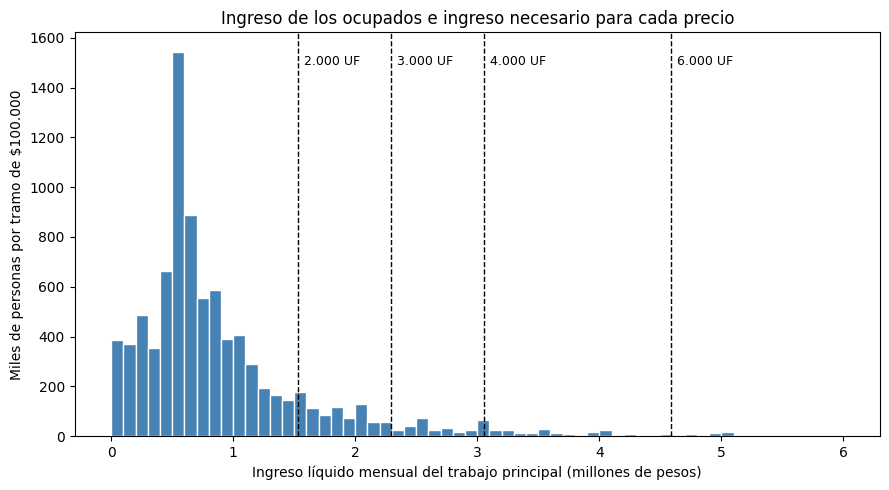

In [40]:
en_rango = candidatos[candidatos["ing_t_p"] <= 6_000_000]   # se omiten los ingresos mayores a $6 millones

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(en_rango["ing_t_p"] / 1e6, bins=60, range=(0, 6), weights=en_rango["fact_cal_esi"] / 1000,
        color="steelblue", edgecolor="white")
for precio in PRECIOS_UF:   # línea vertical en el ingreso necesario para cada precio (sección 7.2)
    ingreso = ingreso_necesario.loc[precio, "ingreso_necesario"] / 1e6
    ax.axvline(ingreso, color="black", linestyle="--", linewidth=1)
    ax.text(ingreso + 0.05, ax.get_ylim()[1] * 0.92, f"{formato_chileno(precio)} UF", fontsize=9)
ax.set_title("Ingreso de los ocupados e ingreso necesario para cada precio")
ax.set_xlabel("Ingreso líquido mensual del trabajo principal (millones de pesos)")
ax.set_ylabel(r"Miles de personas por tramo de \$100.000")
plt.tight_layout()
plt.show()

**Interpretación:**

- **La mayoría de los ocupados gana menos de \$1 millón al mes**, con la mayor concentración entre \$500.000 y \$600.000.
- **Las líneas marcan el ingreso necesario:** \$1,53 millones para 2.000 UF y \$4,58 millones para 6.000 UF.
- Casi toda la distribución queda a la izquierda de la primera línea, y por eso solo el 14,3% alcanza 2.000 UF.
- El gráfico omite al 0,6% con ingresos sobre \$6 millones.

## 8.2 Porcentaje que alcanza 2.000 UF, por región (barras horizontales)

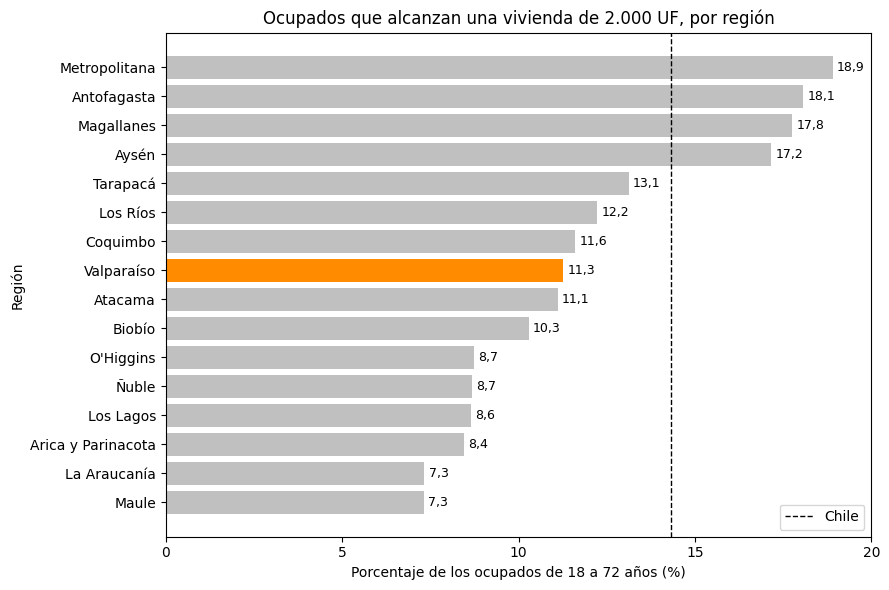

In [41]:
datos = alcanza_region[2000].sort_values()
colores = ["darkorange" if region == "Valparaíso" else "silver" for region in datos.index]   # Valparaíso destacada

fig, ax = plt.subplots(figsize=(9, 6))
barras = ax.barh(datos.index, datos.values, color=colores)
ax.bar_label(barras, labels=[formato_chileno(valor, 1) for valor in datos.values], padding=3, fontsize=9)
ax.axvline(alcanza_pais.loc[2000, "porcentaje"], color="black", linestyle="--", linewidth=1, label="Chile")
ax.set_xticks(range(0, 21, 5))   # marcas del eje en números enteros
ax.set_title("Ocupados que alcanzan una vivienda de 2.000 UF, por región")
ax.set_xlabel("Porcentaje de los ocupados de 18 a 72 años (%)")
ax.set_ylabel("Región")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretación:** Solo cuatro regiones superan el promedio del país: Metropolitana, Antofagasta, Magallanes y Aysén. La Región de Valparaíso, en naranjo, tiene 11,3% y está en el lugar 8 de 16. Los menores porcentajes, bajo 9%, están en O'Higgins, Ñuble, Los Lagos, Arica y Parinacota, La Araucanía y Maule.

## 8.3 Porcentaje que alcanza cada precio, según formalidad del empleo (barras agrupadas)

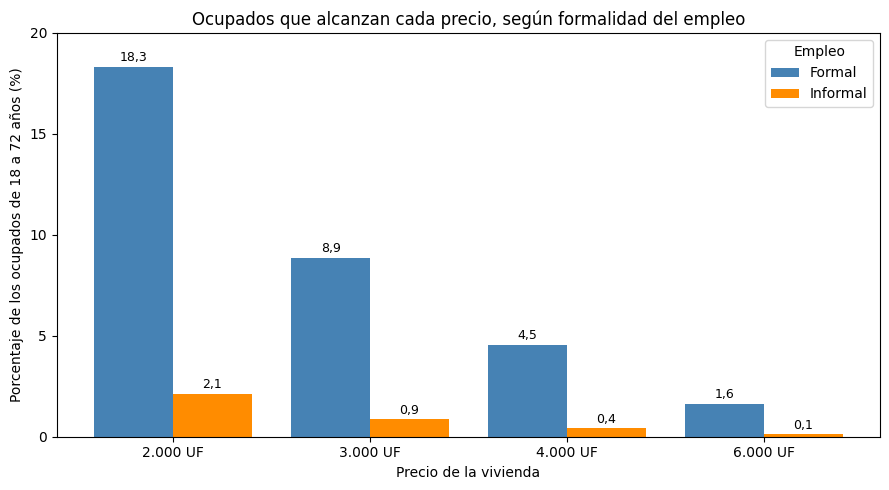

In [42]:
formalidad = porcentaje_por_grupo(candidatos, "nombre_formalidad")   # filas: Formal e Informal; columnas: precios
x = np.arange(len(PRECIOS_UF))                                         # posición de cada grupo de barras

fig, ax = plt.subplots(figsize=(9, 5))
for desplazamiento, categoria, color in [(-0.2, "Formal", "steelblue"), (0.2, "Informal", "darkorange")]:
    valores = formalidad.loc[categoria]
    barras = ax.bar(x + desplazamiento, valores, width=0.4, label=categoria, color=color)
    ax.bar_label(barras, labels=[formato_chileno(valor, 1) for valor in valores], padding=2, fontsize=9)
ax.set_xticks(x, [f"{formato_chileno(precio)} UF" for precio in PRECIOS_UF])
ax.set_yticks(range(0, 21, 5))
ax.set_title("Ocupados que alcanzan cada precio, según formalidad del empleo")
ax.set_xlabel("Precio de la vivienda")
ax.set_ylabel("Porcentaje de los ocupados de 18 a 72 años (%)")
ax.legend(title="Empleo")
plt.tight_layout()
plt.show()

**Interpretación:** La formalidad es lo que más separa a los grupos: el 18,3% de los formales alcanza 2.000 UF, frente al 2,1% de los informales, casi nueve veces menos; para 6.000 UF, los informales casi no aparecen (0,1%). Además, a los informales les cuesta más acreditar su renta ante el banco, así que su acceso real probablemente es aún menor.

## 8.4 Efecto del subsidio a la tasa (barras agrupadas)

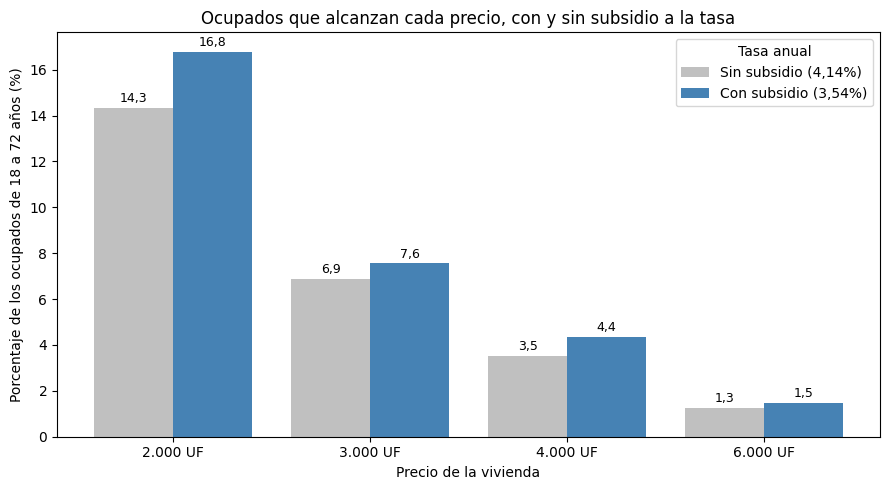

In [43]:
fig, ax = plt.subplots(figsize=(9, 5))
for desplazamiento, columna, nombre, color in [(-0.2, "sin_subsidio", "Sin subsidio (4,14%)", "silver"),
                                               (0.2, "con_subsidio", "Con subsidio (3,54%)", "steelblue")]:
    valores = efecto_subsidio[columna]
    barras = ax.bar(x + desplazamiento, valores, width=0.4, label=nombre, color=color)
    ax.bar_label(barras, labels=[formato_chileno(valor, 1) for valor in valores], padding=2, fontsize=9)
ax.set_xticks(x, [f"{formato_chileno(precio)} UF" for precio in PRECIOS_UF])
ax.set_title("Ocupados que alcanzan cada precio, con y sin subsidio a la tasa")
ax.set_xlabel("Precio de la vivienda")
ax.set_ylabel("Porcentaje de los ocupados de 18 a 72 años (%)")
ax.legend(title="Tasa anual")
plt.tight_layout()
plt.show()

**Interpretación:** El subsidio sube el porcentaje en todos los precios, pero poco: el mayor salto es en 2.000 UF (de 14,3% a 16,8%), y en los precios altos las dos barras son casi iguales. Ayuda sobre todo a quienes ya estaban cerca de poder comprar una vivienda de menor precio.

## 8.5 Tasa hipotecaria y acceso a 2.000 UF, 2009 a 2026 (líneas)

Se usan dos paneles con el mismo eje de tiempo, en vez de dos ejes verticales en un mismo gráfico, para no sugerir una relación que dependa de las escalas elegidas.

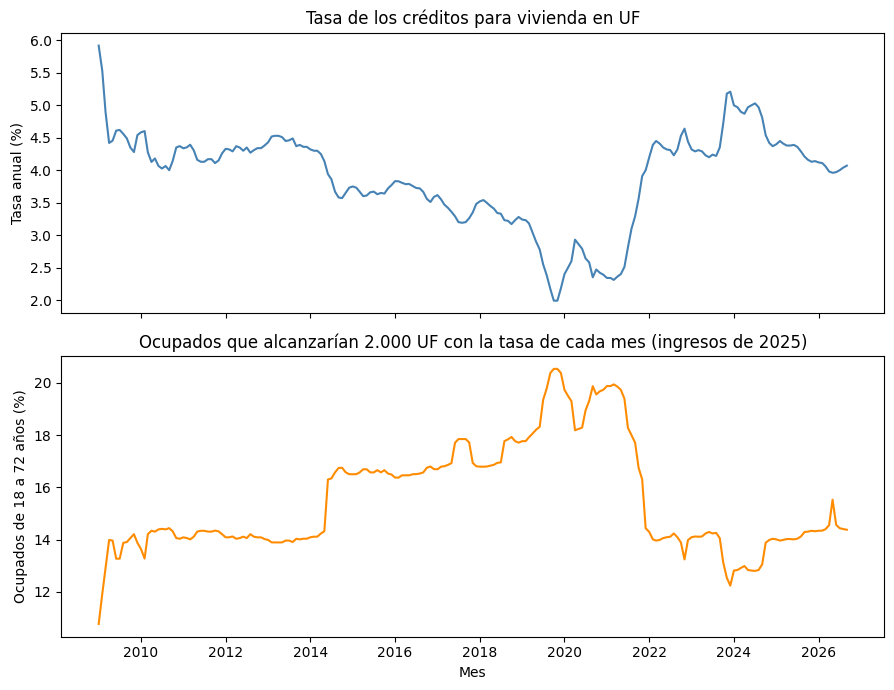

In [44]:
fig, (ax_tasa, ax_acceso) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)   # sharex: el mismo eje de tiempo

ax_tasa.plot(historico.index, historico["tasa"], color="steelblue")
ax_tasa.set_title("Tasa de los créditos para vivienda en UF")
ax_tasa.set_ylabel("Tasa anual (%)")

ax_acceso.plot(historico.index, historico["alcanza_2000"], color="darkorange")
ax_acceso.set_title("Ocupados que alcanzarían 2.000 UF con la tasa de cada mes (ingresos de 2025)")
ax_acceso.set_ylabel("Ocupados de 18 a 72 años (%)")
ax_acceso.set_xlabel("Mes")
plt.tight_layout()
plt.show()

**Interpretación:**

- **La tasa y el acceso se mueven en sentido contrario.**
- Cuando la tasa llegó a su mínimo en octubre de 2019 (1,99%), el porcentaje que alcanzaría 2.000 UF subió a 20,5%; cuando subió a 5,21% a fines de 2023, cayó a cerca de 12%.
- Desde 2024 la tasa bajó a cerca de 4% y el acceso volvió a cerca de 14%.
- **Escalones:** la línea inferior avanza en escalones porque muchos ocupados declaran ingresos redondos (como \$1.000.000): cuando la tasa cambia, grupos completos cruzan el umbral a la vez.

# 9. Implementación de dos paradigmas

## 9.1 Tarea común

**Tarea:** calcular el porcentaje ponderado de ocupados de 18 a 72 años que alcanza cada precio (2.000, 3.000, 4.000 y 6.000 UF) en el escenario base, sin y con subsidio.

Es la misma tarea que resolvió Pandas en las secciones 7.3 y 7.5, así que los tres resultados deben coincidir. Las dos soluciones parten de los mismos datos (edad, ingreso y factor de expansión de cada persona) y reutilizan las fórmulas de la sección 2, que ya son funciones puras. Lo que cambia es cómo se organizan los datos y las operaciones:

| | Programación funcional (9.2) | Programación orientada a objetos (9.3) |
|---|---|---|
| Datos | Lista de diccionarios que no se modifican | Objetos con estado propio (atributos) |
| Operaciones | Funciones puras combinadas con `map`, `filter` y `reduce` | Métodos de cada clase, que se llaman entre sí |
| Idea central | Transformar los datos paso a paso | Modelar las entidades del problema y sus relaciones |

## 9.2 Solución con programación funcional

El cálculo es un *pipeline* de transformaciones, como en el módulo 4 del curso:

`personas` → **map** (agrega el precio máximo a cada registro) → **filter** (deja a quienes alcanzan el precio) → **reduce** (suma sus factores) → porcentaje

Características del paradigma que se usan:

- **Funciones puras:** dependen solo de sus argumentos y de constantes que no cambian, y no modifican nada fuera de ellas.
- **Inmutabilidad:** `con_precio_maximo` crea un diccionario nuevo con `{**persona, ...}` en vez de modificar el original.
- **Funciones como valores y de orden superior:** `alcanza(precio)` devuelve una función, que `porcentaje` recibe como argumento; `map`, `filter` y `reduce` (importada desde `functools` en 4.1) también reciben funciones.
- **Composición:** `precio_maximo_persona` combina `plazo_permitido` (2.5) y `precio_maximo` (7.2).

In [45]:
# Datos de entrada: to_dict("records") convierte la tabla en una lista de diccionarios, uno por persona
personas = candidatos[["edad", "ing_t_p", "fact_cal_esi"]].to_dict("records")


def precio_maximo_persona(persona, tasa_pct):
    """Función pura: precio máximo (UF) de una persona con el plazo base."""
    plazo = plazo_permitido(persona["edad"], PLAZO_BASE)
    return precio_maximo(persona["ing_t_p"], plazo, tasa_pct)


def con_precio_maximo(persona, tasa_pct):
    """Devuelve un registro NUEVO con el precio máximo; el original no cambia."""
    return {**persona, "precio_maximo": precio_maximo_persona(persona, tasa_pct)}


def alcanza(precio):
    """Función de orden superior: devuelve una función que indica si una persona alcanza `precio`."""
    return lambda persona: persona["precio_maximo"] >= precio


def suma_factores(registros):
    """Suma los factores de expansión con reduce."""
    return reduce(lambda acumulado, persona: acumulado + persona["fact_cal_esi"], registros, 0)


def porcentaje(registros, condicion):
    """Porcentaje ponderado de los registros que cumplen `condicion` (una función)."""
    return 100 * suma_factores(filter(condicion, registros)) / suma_factores(registros)


print(len(personas), "registros | primero:", personas[0])
print("Prueba de función pura (misma entrada, mismo resultado):",
      round(precio_maximo_persona(personas[0], TASA_BASE), 1), round(precio_maximo_persona(personas[0], TASA_BASE), 1))

37811 registros | primero: {'edad': 32, 'ing_t_p': 526629.782042534, 'fact_cal_esi': 553.603591694455}
Prueba de función pura (misma entrada, mismo resultado): 689.3 689.3


In [46]:
def porcentajes_funcional(registros, tasa_pct):
    """Pipeline: map agrega el precio máximo; filter y reduce calculan el porcentaje que alcanza cada precio."""
    evaluados = list(map(lambda persona: con_precio_maximo(persona, tasa_pct), registros))
    return {precio: porcentaje(evaluados, alcanza(precio)) for precio in PRECIOS_UF}


resultado_funcional = pd.DataFrame({
    "sin_subsidio": porcentajes_funcional(personas, TASA_BASE),
    "con_subsidio": porcentajes_funcional(personas, TASA_CON_SUBSIDIO),
})
print("Primer registro después del cálculo:", personas[0])   # no tiene "precio_maximo": no se modificó
resultado_funcional.round(1)

Primer registro después del cálculo: {'edad': 32, 'ing_t_p': 526629.782042534, 'fact_cal_esi': 553.603591694455}


,sin_subsidio,con_subsidio
2000,14.3,16.8
3000,6.9,7.6
4000,3.5,4.4
6000,1.3,1.5


**Interpretación:** El pipeline entrega los mismos porcentajes que Pandas (se comprueba en 9.4). La prueba de la primera celda devuelve dos veces 689,3 UF, el mismo valor de la primera fila de la sección 7.2, y el primer registro sigue igual después del cálculo: no tiene la clave `precio_maximo`, porque `map` trabajó sobre copias.

## 9.3 Solución con programación orientada a objetos

**Diseño.** Siguiendo los pasos de abstracción del curso (clases → atributos → métodos → relaciones → implementación):

| Clase | Atributos (estado) | Métodos (comportamiento) | Relación |
|---|---|---|---|
| `Ocupado` | `edad`, `_ingreso` (protegido), `factor` | `ingreso` (propiedad con validación), `__str__()` | Los créditos lo reciben como argumento |
| `CreditoHipotecario` | `_tasa_pct` (protegido), `plazo_deseado`; las reglas del banco y la UF como atributos de clase | `tasa_pct` (propiedad de solo lectura), `plazo_para()`, `dividendo_maximo()`, `precio_maximo()`, `alcanza()` | Clase padre |
| `CreditoConSubsidio` | `rebaja` | Sobrescribe `tasa_pct` | **Es un** `CreditoHipotecario` (herencia) |
| `Evaluacion` | `credito`, `ocupados` | `porcentaje_que_alcanza()` | **Tiene un** crédito y una lista de ocupados (agregación) |

Principios que se usan:

- **Encapsulamiento:** `_ingreso` y `_tasa_pct` son de uso interno. El ingreso se valida en su *setter* (no acepta valores negativos) y la tasa solo se puede leer.
- **Abstracción:** `Evaluacion` solo necesita que el crédito sepa responder `alcanza()`; no conoce las fórmulas.
- **Herencia y sobrescritura:** `CreditoConSubsidio` hereda todo de `CreditoHipotecario` y solo redefine `tasa_pct`.
- **Polimorfismo:** `Evaluacion` usa los dos créditos de la misma forma, y cada uno responde con su propia tasa.
- **Agregación:** `Evaluacion` recibe un crédito y una lista de objetos `Ocupado` ya creados, que existen sin ella (la misma lista se usa en las tres evaluaciones).

In [47]:
class Ocupado:
    """Persona ocupada que puede pedir un crédito: edad, ingreso líquido mensual (pesos) y factor de expansión."""

    def __init__(self, edad, ingreso, factor):
        self.edad = edad
        self.ingreso = ingreso   # pasa por el setter, que valida el valor
        self.factor = factor

    @property
    def ingreso(self):
        return self._ingreso

    @ingreso.setter
    def ingreso(self, valor):
        if valor < 0:
            raise ValueError("El ingreso no puede ser negativo")
        self._ingreso = valor

    def __str__(self):
        return f"Ocupado de {self.edad:.0f} años con un ingreso de {formato_pesos(self.ingreso)}"

In [48]:
class CreditoHipotecario:
    """Crédito de BancoEstado (sección 2.5) con una tasa anual (%) y un plazo deseado (años)."""

    porcentaje_dividendo = PORCENTAJE_DIVIDENDO   # atributos de clase: valores iguales para todos los créditos
    financiamiento = FINANCIAMIENTO
    valor_uf = UF_REFERENCIA                      # pesos por UF (sección 6.8)

    def __init__(self, tasa_pct, plazo_deseado=PLAZO_BASE):
        self._tasa_pct = tasa_pct
        self.plazo_deseado = plazo_deseado

    @property
    def tasa_pct(self):
        """Tasa anual que paga la persona (solo lectura: no tiene setter)."""
        return self._tasa_pct

    def plazo_para(self, ocupado):
        return plazo_permitido(ocupado.edad, self.plazo_deseado)

    def dividendo_maximo(self, ocupado):
        """Mayor dividendo (UF) que permite la regla del 25%."""
        return self.porcentaje_dividendo * ocupado.ingreso / self.valor_uf

    def precio_maximo(self, ocupado):
        credito = credito_maximo(self.dividendo_maximo(ocupado), tasa_mensual(self.tasa_pct / 100),
                                 12 * self.plazo_para(ocupado))
        return credito / self.financiamiento

    def alcanza(self, ocupado, precio):
        return self.precio_maximo(ocupado) >= precio

In [49]:
class CreditoConSubsidio(CreditoHipotecario):
    """Es un crédito hipotecario, pero con la tasa rebajada por el subsidio (Ley 21.748)."""

    def __init__(self, tasa_pct, plazo_deseado=PLAZO_BASE, rebaja=SUBSIDIO):
        super().__init__(tasa_pct, plazo_deseado)
        self.rebaja = rebaja

    @property
    def tasa_pct(self):   # sobrescribe la propiedad de la clase padre
        return self._tasa_pct - self.rebaja

In [50]:
class Evaluacion:
    """Tiene un crédito y una lista de ocupados; calcula qué porcentaje de ellos alcanza un precio."""

    def __init__(self, credito, ocupados):
        self.credito = credito
        self.ocupados = ocupados

    def porcentaje_que_alcanza(self, precio):
        total = 0
        alcanzan = 0
        for ocupado in self.ocupados:   # recorre los objetos y acumula sus factores de expansión
            total += ocupado.factor
            if self.credito.alcanza(ocupado, precio):
                alcanzan += ocupado.factor
        return 100 * alcanzan / total

In [51]:
# Prueba con la primera persona y con un dato inválido
primera = candidatos.iloc[0]
ejemplo = Ocupado(primera["edad"], primera["ing_t_p"], primera["fact_cal_esi"])
credito_base = CreditoHipotecario(TASA_BASE)
print(ejemplo, "| plazo:", credito_base.plazo_para(ejemplo), "años | precio máximo:",
      round(credito_base.precio_maximo(ejemplo), 1), "UF")

try:
    ejemplo.ingreso = -1000   # el objeto protege su estado: no acepta un ingreso negativo
except ValueError as error:
    print("Error:", error)

Ocupado de 32 años con un ingreso de $526.630 | plazo: 25 años | precio máximo: 689.3 UF
Error: El ingreso no puede ser negativo


In [52]:
# DataFrame -> objetos, como en la práctica 1 del curso
ocupados_obj = []
for _, fila in candidatos[["edad", "ing_t_p", "fact_cal_esi"]].iterrows():
    ocupados_obj.append(Ocupado(fila["edad"], fila["ing_t_p"], fila["fact_cal_esi"]))
print("Objetos Ocupado creados:", len(ocupados_obj))

# Polimorfismo: los dos créditos se usan igual, pero cada uno responde con su propia tasa
resultado_poo = {}
for nombre, credito in [("sin_subsidio", CreditoHipotecario(TASA_BASE)), ("con_subsidio", CreditoConSubsidio(TASA_BASE))]:
    evaluacion = Evaluacion(credito, ocupados_obj)
    resultado_poo[nombre] = {precio: evaluacion.porcentaje_que_alcanza(precio) for precio in PRECIOS_UF}
    print(f"{nombre}: tasa de {formato_chileno(credito.tasa_pct, 2)}%")
resultado_poo = pd.DataFrame(resultado_poo)

# Otro plazo no requiere cambiar el código: el plazo es un atributo del crédito
a_30_anios = Evaluacion(CreditoHipotecario(TASA_BASE, plazo_deseado=30), ocupados_obj)
print(f"Con 30 años alcanza 2.000 UF el {formato_chileno(a_30_anios.porcentaje_que_alcanza(2000), 1)}% (sección 7.4: 17,3%)")
resultado_poo.round(1)

Objetos Ocupado creados: 37811
sin_subsidio: tasa de 4,14%
con_subsidio: tasa de 3,54%
Con 30 años alcanza 2.000 UF el 17,3% (sección 7.4: 17,3%)


,sin_subsidio,con_subsidio
2000,14.3,16.8
3000,6.9,7.6
4000,3.5,4.4
6000,1.3,1.5


**Interpretación:**

- **Prueba:** el objeto de prueba da el mismo precio máximo que las otras soluciones (689,3 UF) y rechaza un ingreso negativo sin detener el notebook.
- **Polimorfismo:** la misma clase `Evaluacion` calcula los dos escenarios: con `CreditoHipotecario` usa la tasa de 4,14% y con `CreditoConSubsidio`, la de 3,54%, sin que su código cambie.
- **Otro plazo:** un crédito a 30 años se evalúa solo creando otro objeto, y da el mismo 17,3% de la sección 7.4.

## 9.4 Verificación: los tres enfoques entregan el mismo resultado

In [53]:
resultado_pandas = efecto_subsidio[["sin_subsidio", "con_subsidio"]]   # sección 7.5

comparacion = pd.DataFrame({
    "pandas_sin": resultado_pandas["sin_subsidio"], "funcional_sin": resultado_funcional["sin_subsidio"],
    "poo_sin": resultado_poo["sin_subsidio"], "pandas_con": resultado_pandas["con_subsidio"],
    "funcional_con": resultado_funcional["con_subsidio"], "poo_con": resultado_poo["con_subsidio"],
})
comparacion.round(2)

,pandas_sin,funcional_sin,poo_sin,pandas_con,funcional_con,poo_con
2000,14.32,14.32,14.32,16.79,16.79,16.79
3000,6.90,6.90,6.90,7.55,7.55,7.55
4000,3.52,3.52,3.52,4.36,4.36,4.36
6000,1.26,1.26,1.26,1.46,1.46,1.46


**Interpretación:** Los tres enfoques entregan los mismos porcentajes en los cuatro precios, sin subsidio y con subsidio: las dos soluciones resuelven la misma tarea que Pandas.

# 10. Comparación entre paradigmas

| Criterio | Programación funcional (9.2) | Programación orientada a objetos (9.3) |
|---|---|---|
| **Legibilidad** | El cálculo se lee como una secuencia: `map(con_precio_maximo)` → `filter(alcanza(precio))` → `reduce`. Cuesta un poco más entender una función que devuelve otra función, como `alcanza(precio)`. | Los nombres siguen el problema: `credito.alcanza(ocupado, precio)` se lee casi como una frase. Pero para seguir un resultado hay que pasar por cuatro clases y saber qué método llama a cuál. |
| **Modularidad** | Cada función hace una sola cosa (`precio_maximo_persona`, `alcanza`, `suma_factores`, `porcentaje`) y se combinan por composición. | Cada clase reúne datos y operaciones de una entidad: las reglas del banco están en `CreditoHipotecario` y el recorrido de las personas, en `Evaluacion`. |
| **Reutilización** | Las funciones puras se reutilizan sin cambios: `precio_maximo` (7.2) sirve igual para una columna de pandas y para un solo registro. | La herencia reutiliza todo `CreditoHipotecario`: `CreditoConSubsidio` solo redefine `tasa_pct`. |
| **Mantenibilidad** | Cada cambio se hace en una función pequeña, pero un dato nuevo hay que pasarlo por toda la cadena: para evaluar otro plazo habría que agregar un parámetro a `precio_maximo_persona`, `con_precio_maximo` y `porcentajes_funcional`. | Basta crear `CreditoHipotecario(TASA_BASE, plazo_deseado=30)`, porque el plazo es un atributo del crédito (9.3). Una regla nueva, como un tope de precio para el subsidio, solo cambiaría `CreditoConSubsidio`, sin tocar `Evaluacion`. |

| Criterio | Programación funcional (9.2) | Programación orientada a objetos (9.3) |
|---|---|---|
| **Manejo del estado** | No hay estado que cambie: `con_precio_maximo` crea un diccionario nuevo con `{**persona, ...}`, y `personas[0]` sigue igual después del cálculo (9.2). | El estado vive en los objetos y está protegido: `_tasa_pct` es de solo lectura y el *setter* de `ingreso` rechaza valores negativos. `porcentaje_que_alcanza` usa acumuladores (`total += ...`) que cambian en cada vuelta. |
| **Facilidad de prueba** | Una función pura se prueba con una sola llamada: con los mismos argumentos siempre da lo mismo (`precio_maximo_persona(personas[0], TASA_BASE)`). | Para probar un método hay que crear antes los objetos que necesita (un `Ocupado` y un crédito). A cambio, las validaciones se prueban directamente (`ejemplo.ingreso = -1000`). |
| **Adecuación al problema** | Muy adecuada: la tarea es transformar una tabla en porcentajes, sin entidades que cambien en el tiempo. Es la misma lógica de Pandas: filtrar, transformar y sumar. | Menos adecuada para este cálculo: obliga a crear 37.811 objetos con `iterrows` y recorrerlos uno por uno. Sería más adecuada si el sistema creciera, con varios bancos, productos o reglas. |

# 11. Conclusiones, referencias y uso de IA

## 11.1 Respuesta a la pregunta principal

**Con su sueldo, solo una minoría de los ocupados de 18 a 72 años puede financiar viviendas de estos precios.**

- **Escenario base** (tasa de 4,14%, 25 años y pie de 10%): el 14,3% alcanza una de 2.000 UF y apenas el 1,3%, una de 6.000 UF.
- El acceso depende mucho del grupo de trabajadores y es sensible a la tasa y al plazo.
- El subsidio a la tasa lo mejora poco.

## 11.2 Síntesis de los resultados

1. **Ingreso por grupos:** la mediana nacional es \$680.000. Es menor en las mujeres, en los jóvenes y los mayores, en quienes no son proveedores principales y, sobre todo, en los informales (\$360.000 frente a \$797.924 de los formales). La Región de Valparaíso (\$630.266) está bajo la mediana del país.
2. **Acceso por precio:** alcanzan 2.000, 3.000, 4.000 y 6.000 UF el 14,3%, 6,9%, 3,5% y 1,3% de los ocupados de 18 a 72 años. El acceso a 2.000 UF va de 7,3% en Maule y La Araucanía a 18,9% en la Metropolitana, y de 2,1% en los informales a 18,3% en los formales.
3. **Tasa y plazo:** según el escenario, el acceso a 2.000 UF va de 10,3% (5,21% y 20 años) a 24,4% (1,99% y 30 años). Entre 2009 y 2026, solo por la tasa, habría variado entre 10,8% y 20,5%.
4. **Subsidio:** la rebaja de 0,6 puntos sube el acceso a 2.000 UF de 14,3% a 16,8%, unas 219 mil personas más; la mayoría vive en la Región Metropolitana y la segunda región que más se beneficia es Valparaíso.

## 11.3 Limitaciones

- **Solo ingresos del trabajo principal:** la ESI no mide ahorro, deudas ni otros ingresos. Se supone que todos tienen el pie y que no tienen otras deudas, y no se suma el ingreso de otros trabajos ni de otras personas del hogar. Por eso los porcentajes son un piso: el acceso de los hogares puede ser mayor.
- **Reglas de un solo banco:** la aprobación real también depende de la antigüedad laboral, los antecedentes comerciales y la evaluación del banco, que la ESI no mide; a los informales, además, les cuesta más acreditar su renta.
- **Tasa promedio:** la tasa del Banco Central es un promedio de la Región Metropolitana y se aplica a todas las regiones, aunque cada persona puede recibir ofertas distintas.
- **Subsidio:** se supone la rebaja máxima y una vivienda nueva, y no se consideran los cupos limitados del beneficio.
- **Precisión:** no se calculan errores estándar ni intervalos de confianza, porque requieren el diseño muestral completo de la encuesta.

## 11.4 Paradigma más apropiado

Para esta tarea, la **programación funcional** resultó más apropiada (sección 10).

- **El problema consiste en transformar datos** (filtrar a las personas, calcular su precio máximo y sumar sus factores), y eso se expresa directamente con funciones puras y `map`, `filter` y `reduce`, sin estado que cambie y con funciones fáciles de probar por separado.
- **Sus funciones se integran sin cambios con Pandas:** `precio_maximo` sirvió tanto para columnas completas (sección 7) como para un solo registro (9.2).
- **La programación orientada a objetos** sería preferible si el proyecto creciera hacia un simulador con varios bancos, productos y reglas, donde conviene que cada entidad proteja su propio estado.
- **No son excluyentes:** las dos soluciones dan el mismo resultado (9.4), y la versión orientada a objetos usa dentro de sus métodos las funciones puras de la sección 2.

## 11.5 Referencias (APA 7)

- Banco Central de Chile. (s. f.-a). *Indicadores de reajustabilidad diario* [Cuadro estadístico]. Base de Datos Estadísticos. Recuperado el 26 de octubre de 2026, de https://si3.bcentral.cl/Siete/ES/Siete/Cuadro/CAP_PRECIOS/MN_CAP_PRECIOS/UF_IVP_DIARIO/UF_IVP_DIARIO
- Banco Central de Chile. (s. f.-b). *Tasa y flujo de colocación promedio vivienda* [Cuadro estadístico]. Base de Datos Estadísticos. Recuperado el 26 de octubre de 2026, de https://si3.bcentral.cl/Siete/ES/Siete/Cuadro/CAP_TASA_INTERES/MN_TASA_INTERES_09/TSF_27A/T5224
- Banco Central de Chile. (s. f.-c). *Términos y condiciones de uso de la Base de Datos Estadísticos*. https://si3.bcentral.cl/estadisticas/Principal1/Web_Services/terminos_condiciones.html
- BancoEstado. (s. f.-a). *Créditos hipotecarios*. Recuperado el 26 de octubre de 2026, de https://www.bancoestado.cl/content/bancoestado-public/cl/es/home/home/productos-/creditos/creditos-hipotecarios.html
- BancoEstado. (s. f.-b). *Póliza de seguros colectivos desgravamen hipotecario N.° 22308* [Documento PDF]. Recuperado el 26 de octubre de 2026, de https://www.bancoestado.cl/content/dam/bancoestado-public/pdf/condiciones-seguros-hipotecarios/Desgravamen-BancoEstado-22308.pdf
- Cano, S. (2026). *Paradigmas de Programación* [Repositorio de GitHub del curso ICD 2346]. https://github.com/SandraCano-PUCV/ParadigmasProgramacion
- Instituto Nacional de Estadísticas. (s. f.-a). *Encuesta Suplementaria de Ingresos 2025: base de datos de personas* [Conjunto de datos CSV]. Recuperado el 11 de octubre de 2026, de https://www.ine.gob.cl/docs/default-source/encuesta-suplementaria-de-ingresos/bbdd/csv_esi/2025/esi_2025_personas.csv?sfvrsn=7f734fe_4&download=true
- Instituto Nacional de Estadísticas. (s. f.-b). *Términos de uso y licencia de datos abiertos*. https://www.ine.gob.cl/terminos-de-uso-y-licencia-de-datos-abiertos
- Instituto Nacional de Estadísticas. (2026a). *Manual de usuario de base de datos: Encuesta Suplementaria de Ingresos (ESI) 2025* (Versión 1.0). https://www.ine.gob.cl/estadisticas/sociales/ingresos-y-gastos/encuesta-suplementaria-de-ingresos
- Instituto Nacional de Estadísticas. (2026b). *Libro de códigos base de datos Encuesta Nacional de Empleo (ENE)*. https://www.ine.gob.cl/docs/default-source/ocupacion-y-desocupacion/bbdd/libro-de-codigos/codigos-ene-2020.pdf?sfvrsn=54753851_86
- Ivorra, C. (s. f.). *Las matemáticas de una hipoteca* [Apuntes]. http://www.uv.es/ivorra
- Ley N.° 21.836. (2026, 17 de agosto). *Extiende vigencia y aumenta cobertura de la Ley N.° 21.748 y modifica normas que indica*. Diario Oficial de la República de Chile, N.° 44.526. https://www.diariooficial.interior.gob.cl/publicaciones/2026/08/17/44526/01/2854867.pdf
- Ministerio de Vivienda y Urbanismo. (2025, 20 de mayo). *Ministro Montes valora aprobación de ley que crea subsidio a la tasa de interés hipotecaria*. https://www.minvu.gob.cl/noticia/ministro-montes-valora-aprobacion-de-ley-que-crea-subsidio-a-la-tasa-de-interes-hipotecaria/
- Python Software Foundation. (s. f.). *functools: Higher-order functions and operations on callable objects*. https://docs.python.org/3/library/functools.html
- Documentación de [pandas](https://pandas.pydata.org/docs/), [NumPy](https://numpy.org/doc/stable/) y [Matplotlib](https://matplotlib.org/stable/).

## 11.6 Declaración de uso de inteligencia artificial

- **Herramienta:** Claude (Anthropic). No se usaron otras herramientas de inteligencia artificial.
- **Propósito:** proponer la estructura, redactar y simplificar parte del código y de los textos, revisar las fuentes y preparar la defensa.
- **Verificación:** ejecutamos el notebook completo en Google Colab y revisamos cada resultado. Reproduce el ingreso medio y el mediano del INE (6.7) y el ejemplo del apunte de Ivorra (2.4), los archivos del Banco Central coinciden con los de la BDE y las tres soluciones entregan el mismo resultado (9.4).